# Poyecto 2D

Ejecución para CIFAR (2) y para MNIST (2)

Variación de la función de pérdida (opción clásica y opción con MMD)

Aplicación del KL Annealing en la opción clásica (kl) -> empezar con los pesos en 0 e ir subiendo (warmup_steps=2000)

Aumentar el peso de 1 a 10000 en MMD

CAMBIOS:

- Creación de la función de pérdida con MMD
- Uso de peso 10000 en MMD
- KL Annealing
- Redimensionamiento de MNIST a 32×32 (ya lo hace el profesor)
- Funciones de representación universales detectando los canales de la imagen (1 canal → MNIST, 3 canales → CIFAR)
- Función de entrenamiento unificada
- Recalculo de z en el paso MMD del entrenamiento
- Dimensión del espacio latente: 32 (MNIST) vs 128 (CIFAR) (ya lo hace el profesor)
- Número de épocas: 20 (MNIST) vs 50 (CIFAR) (ya lo hace el profesor)
- Curva de aprendizaje
- ¿¿¿Reducción a KL en la fórmula: torch.mean vs torch.sum + torch.mean???
- Elección del Kernel IMQ por encima del RBF para MMD


TAREAS:

- Corregir comentarios de las funciones generales
- Explicación de conseguir MMD
- Explicación del KL Annealing
- Justificar mejor la elección de peso 10000 en MMD
- Conclusiones


CONVERSACIÓN CON NAUHEL:
- Probar con fashionminst
- Aumentar convoluciones? (Para captar mejor las imagenes de datasets como CIFAR)
- Para mejorar quizás probar los hiperparámetros

## Configuración global

### Importación de librerías

In [1]:
import os, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

device = "cuda" if torch.cuda.is_available() else "cpu"

### Funciones de pérdida

En el VAE, para que el modelo funcione perfectamente, la divergencia KL y el error de reconstrucción deben tener prácticamente el mismo peso. Por eso el estándar es que $\beta$ (Beta) sea 1.0, ya que los valores que devuelve la fórmula del KL suelen ser numéricamente grandes y compiten de tú a tú con el error de reconstrucción (MSE).

En cambio, la fórmula del MMD devuelve números mucho más pequeños que la fórmula del KL. Si le pusiéramos un peso de 1, el valor del MMD sería muy diminuto comparado con la reconstrucción, por lo que la red neuronal lo ignoraría por completo. Para solucionarlo, el peso escogido va a ser 10000, con el que obtendremos resultados más acordes a las ejecuciones.

In [ ]:
# FUNCIÓN DE PÉRDIDA KL
def vae_loss_kl(recon_x, x, mu, logvar, beta=1.0):
    recon = F.mse_loss(recon_x, x, reduction="sum")
    kl = -0.5 * torch.mean(torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1))
    return recon + beta * kl, recon, kl
    
# FUNCIÓN DE PÉRDIDA MMD
def compute_kernel(x, y):
    x_size = x.shape[0]
    y_size = y.shape[0]
    dim = x.shape[1]

    x = x.unsqueeze(1)
    y = y.unsqueeze(0)

    tiled_x = x.expand(x_size, y_size, dim)
    tiled_y = y.expand(x_size, y_size, dim)
    
    C = 2.0 * dim * 2.0 
    kernel = C / (1e-7 + C + (tiled_x - tiled_y).pow(2).sum(dim=-1))
    return kernel

def compute_mmd(z, z_prior):
    xx = compute_kernel(z, z)
    yy = compute_kernel(z_prior, z_prior)
    xy = compute_kernel(z, z_prior)

    # Excluimos diagonal antes de hacer mean
    N = xx.shape[0]
    xx_val = (xx.sum() - xx.diag().sum()) / (N * (N - 1))
    yy_val = (yy.sum() - yy.diag().sum()) / (N * (N - 1))
    xy_val = xy.mean()

    return xx_val + yy_val - 2 * xy_val

def vae_loss_mmd(recon_x, x, z, device, lmbda=10000.0):
    recon = F.mse_loss(recon_x, x, reduction="sum")
    z_prior = torch.randn_like(z).to(device)
    mmd_loss = compute_mmd(z, z_prior)
    return recon + lmbda * mmd_loss, recon, lmbda * mmd_loss

### Funciones de representación

In [3]:
# ----------------------------
# Utils: show images
# ----------------------------
@torch.no_grad()
def show_reconstructions(model, loader, n=8, title="Recon"):
    model.eval()
    x, y = next(iter(loader))
    x = x.to(device)[:n]
    
    output = model(x)
    if len(output) == 3:
        recon, mu, logvar = output
    else:
        recon, z = output

    def denorm(t): return (t * 0.5 + 0.5).clamp(0, 1)

    x = denorm(x).cpu()
    recon = denorm(recon).cpu()

    # Detectamos si es MNIST (1 canal) o CIFAR (3 canales)
    is_mnist = (x.shape[1] == 1)

    fig, ax = plt.subplots(2, n, figsize=(2*n, 4))
    for i in range(n):
        if is_mnist:
            # Para MNIST: Quitamos la dimensión del canal y forzamos grises
            ax[0, i].imshow(x[i].squeeze(), cmap="gray"); ax[0, i].axis("off")
            ax[1, i].imshow(recon[i].squeeze(), cmap="gray"); ax[1, i].axis("off")
        else:
            # Para CIFAR: Reordenamos los canales para RGB
            ax[0, i].imshow(x[i].permute(1,2,0)); ax[0, i].axis("off")
            ax[1, i].imshow(recon[i].permute(1,2,0)); ax[1, i].axis("off")
            
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def sample_from_prior(model, n=16, latent_dim=32):
    model.eval()
    z = torch.randn(n, latent_dim, device=device)
    x = model.dec(z)
    x = (x * 0.5 + 0.5).clamp(0, 1).cpu()

    # Detectamos si es MNIST (1 canal) o CIFAR (3 canales)
    is_mnist = (x.shape[1] == 1)

    cols = 8
    rows = math.ceil(n / cols)
    fig, ax = plt.subplots(rows, cols, figsize=(2*cols, 2*rows))
    ax = np.array(ax).reshape(-1)
    for i in range(rows*cols):
        ax[i].axis("off")
        if i < n:
            if is_mnist:
                # Para MNIST: Quitamos la dimensión del canal y forzamos grises
                ax[i].imshow(x[i].squeeze(), cmap="gray")
            else:
                # Para CIFAR: Reordenamos los canales para RGB
                ax[i].imshow(x[i].permute(1,2,0))
    plt.tight_layout()
    plt.show()

### Función de entrenamiento

In [ ]:
def train_model(model, trainloader, testloader, device, epochs=50, loss_type='kl', weight=1.0, warmup_steps=2000):
    """
    Entrena el modelo usando KL o MMD y devuelve el historial de pérdidas para graficar.
    """
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    # Listas para guardar las curvas de aprendizaje
    history_loss = []
    history_recon = []
    history_reg = [] # Regularización (KL o MMD)

    global_step = 0 # Iniciamos el contador de pasos
    
    for ep in range(1, epochs+1):
        model.train()
        tot_loss = tot_rec = tot_reg = 0.0
        
        for x, _ in trainloader:
            x = x.to(device)

            # KL ANNEALING
            if loss_type == 'kl':
                # Sube de 0 a 1 linealmente hasta llegar a warmup_steps
                current_weight = min(1.0, global_step / warmup_steps) * weight
            else:
                current_weight = weight
            
            if loss_type == 'kl':
                recon, mu, logvar = model(x)
                loss, rec, reg = vae_loss_kl(recon, x, mu, logvar, beta=current_weight)
            elif loss_type == 'mmd':
                # Recalculamos el vector latente 'z'
                recon, z = model(x)
                loss, rec, reg = vae_loss_mmd(recon, x, z, device, lmbda=current_weight)
            else:
                raise ValueError("El tipo de loss debe ser 'kl' o 'mmd'")

            opt.zero_grad()
            loss.backward()
            opt.step()

            tot_loss += loss.item()
            tot_rec  += rec.item()
            tot_reg  += reg.item()
            
            global_step += 1

        n_batches = len(trainloader)
        avg_loss = tot_loss/n_batches
        avg_rec = tot_rec/n_batches
        avg_reg = tot_reg/n_batches
        
        # Guardamos en el historial
        history_loss.append(avg_loss)
        history_recon.append(avg_rec)
        history_reg.append(avg_reg)
        
        print(f"Epoch {ep:02d} | loss={avg_loss:.4f} recon={avg_rec:.4f} {loss_type.upper()}={avg_reg:.4f}")

        # Mostramos reconstrucciones cada 10 épocas
        if ep % 10 == 0 or ep == epochs:
            show_reconstructions(model, testloader, n=8, title=f"Reconstrucción {loss_type.upper()} - Epoch {ep}")
            
    return history_loss, history_recon, history_reg

### Funciones del Espacio Latente

In [ ]:
# t-SNE CLÁSICO

def plot_tsne_classes_universal(model, dataloader, device, classes_names=None, title="t-SNE VAE Latent Space"):
    model.eval()
    with torch.no_grad():
        latents = []
        labels = []
        for x, y in dataloader:
            x = x.to(device)
            output = model(x)
            if len(output) == 3:
                _, mu, _ = output
                latent = mu
            else:
                _, latent = output
            latents.append(latent.cpu())
            labels.append(y)
        latents = torch.cat(latents, dim=0).numpy()
        labels = torch.cat(labels, dim=0).numpy()

    tsne = TSNE(n_components=2, random_state=42)
    latents_2d = tsne.fit_transform(latents)

    plt.figure(figsize=(8, 8))
    
    unique_labels = np.unique(labels)
    
    for digit in unique_labels:
        idx = labels == digit
        label_name = classes_names[digit] if classes_names is not None else str(digit)
        plt.scatter(latents_2d[idx, 0], latents_2d[idx, 1], label=label_name, alpha=0.5)
        
    plt.legend()
    plt.title(title)
    plt.grid(True)
    plt.show()


# t-SNE DE PRIOR SAMPLES

def tsne_prior_samples_universal(model, device, is_cifar=True, latent_dim=128):
    with torch.no_grad():
        model.eval()
        n_samples = 1000
        z = torch.randn(n_samples, latent_dim, device=device)
        recon = model.dec(z)
        
        def denorm(t): return (t * 0.5 + 0.5).clamp(0, 1)
        recon = denorm(recon).cpu()
        
        if is_cifar:
            # CIFAR: 3 canales, 32x32
            recon = recon.view(n_samples, 3, 32, 32)
        else:
            # MNIST: 1 canal redimensionado a 32x32
            recon = recon.view(n_samples, 1, 32, 32) 
            recon = recon.numpy().squeeze() 
            recon = (recon > 0.5).astype(int) 
            recon = torch.tensor(recon).view(n_samples, 1, 32, 32).float() 

        enc_out = model.enc(recon.to(device))
        if isinstance(enc_out, tuple):
            latents = enc_out[0].cpu().numpy()  # mu en VAE
        else:
            latents = enc_out.cpu().numpy()     # z en WAE
        
        tsne = TSNE(n_components=2, random_state=42)
        latents_2d = tsne.fit_transform(latents)
        
        plt.figure(figsize=(8, 8))
        plt.scatter(latents_2d[:, 0], latents_2d[:, 1], alpha=0.5, color='purple')
        plt.title("t-SNE of Prior Samples in Latent Space")
        plt.grid(True)
        plt.show()


# t-SNE CON MINIATURAS

@torch.no_grad()
def denorm_universal(t):  
    return (t * 0.5 + 0.5).clamp(0, 1)

def pick_spread_points(emb, n_show=150, seed=42):
    rng = np.random.default_rng(seed)
    idx = np.arange(emb.shape[0])
    rng.shuffle(idx)
    chosen = []
    thr = 0.02 * np.var(emb, axis=0).sum()
    for i in idx:
        if not chosen:
            chosen.append(i); continue
        d2 = np.min(np.sum((emb[chosen] - emb[i])**2, axis=1))
        if d2 > thr:
            chosen.append(i)
        if len(chosen) >= n_show:
            break
    return np.array(chosen)

@torch.no_grad()
def tsne_with_recon_thumbnails_universal(model, loader, device, n_total=3000, n_show=150, zoom=0.8, seed=42):
    model.eval()
    LATENTS = []
    RECON = []

    for x, _ in loader:
        x = x.to(device)
        output = model(x)
        if len(output) == 3:
            recon, mu, logvar = output
            latent = mu
        else:
            recon, latent = output
        LATENTS.append(latent.detach().cpu())
        RECON.append(recon.detach().cpu())
        if sum(t.size(0) for t in LATENTS) >= n_total:
            break

    LATENTS = torch.cat(LATENTS, dim=0)[:n_total].numpy()
    RECON = torch.cat(RECON, dim=0)[:n_total]

    num_channels = RECON.shape[1]
    is_mnist = (num_channels == 1)

    emb = TSNE(n_components=2, random_state=seed, init="pca", learning_rate="auto").fit_transform(LATENTS)
    chosen = pick_spread_points(emb, n_show=n_show, seed=seed)

    if is_mnist:
        thumbs = denorm_universal(RECON[chosen])[:, 0].numpy()
    else:
        thumbs = denorm_universal(RECON[chosen]).permute(0, 2, 3, 1).numpy()

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.set_title(f"t-SNE del latente con reconstrucciones ({'MNIST' if is_mnist else 'CIFAR'})")
    ax.set_xticks([]); ax.set_yticks([])

    for k, i in enumerate(chosen):
        cmap_type = "gray" if is_mnist else None
        ab = AnnotationBbox(OffsetImage(thumbs[k], zoom=zoom, cmap=cmap_type),
                            (emb[i,0], emb[i,1]), frameon=False)
        ax.add_artist(ab)

    ax.set_xlim(emb[chosen,0].min()-5, emb[chosen,0].max()+5)
    ax.set_ylim(emb[chosen,1].min()-5, emb[chosen,1].max()+5)
    plt.tight_layout()
    plt.show()

### Función de interpolación

In [ ]:
@torch.no_grad()
def interpolate_universal(model, dataloader, device, is_cifar=False, n_interp=8, title="Interpolación"):
    model.eval()
    
    # Sacamos un batch del dataloader y cogemos solo las 2 primeras imágenes
    x, _ = next(iter(dataloader))
    x = x[:2].to(device) 
    
    output = model(x)
    if len(output) == 3:
        recon, mu, logvar = output
        z = model.reparameterize(mu, logvar)
    else:
        recon, z = output
    
    z1, z2 = z[0], z[1]
    
    # Generamos los pasos intermedios (línea recta de z1 a z2)
    interp_z = torch.stack([z1 * (1 - alpha) + z2 * alpha for alpha in torch.linspace(0, 1, n_interp)], dim=0) 
    
    # Decodificamos esos puntos intermedios para convertirlos en imágenes
    interp_x = model.dec(interp_z)
    
    # Desnormalizamos
    def denorm(t): return (t * 0.5 + 0.5).clamp(0, 1)
    interp_x = denorm(interp_x).cpu()
    
    fig, ax = plt.subplots(1, n_interp, figsize=(2*n_interp, 2))
    for i in range(n_interp):
        ax[i].axis("off")
        if is_cifar:
            # CIFAR: 3 canales, reordenamos a (Alto, Ancho, Color)
            ax[i].imshow(interp_x[i].permute(1,2,0))
        else:
            # MNIST: 1 canal, quitamos dimensión y ponemos grises
            ax[i].imshow(interp_x[i].squeeze(), cmap="gray")
            
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## MNIST

#### Carga de datos

In [24]:
mnist_transform = transforms.Compose([
    transforms.Resize(32),  # MNIST es 28x28, lo redimensionamos a 32x32
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
mnist_train = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=mnist_transform)
mnist_test  = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=mnist_transform)

batch_size = 128
trainloader_mnist = DataLoader(mnist_train, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
testloader_mnist  = DataLoader(mnist_test,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

#### Modelo MNIST

In [ ]:
# Encoder
class MNISTEncoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),  # 16x16
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(32, 64, 4, 2, 1), # 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1), # 4x4
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
        )
        self.fc_mu = nn.Linear(128*4*4, latent_dim)
        self.fc_logvar = nn.Linear(128*4*4, latent_dim)

    def forward(self, x):
        h = self.net(x).view(x.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)
    
# Decoder
class MNISTDecoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128*4*4)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),
            
            nn.ConvTranspose2d(64, 32, 4, 2, 1),   # 16x16
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),

            nn.ConvTranspose2d(32, 1, 4, 2, 1),    # 32x32
        )

    def forward(self, z):
        h = self.fc(z).view(z.size(0), 128, 4, 4)
        x_logits = self.net(h)
        return torch.tanh(x_logits)
    
# VAE
class MNISTVAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.enc = MNISTEncoder(latent_dim)
        self.dec = MNISTDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.enc(x)
        z = self.reparameterize(mu, logvar)
        recon = self.dec(z)
        return recon, mu, logvar
    

class MNISTEncoderWAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
        )
        self.fc_z = nn.Linear(128*4*4, latent_dim)  # solo una salida

    def forward(self, x):
        h = self.net(x).view(x.size(0), -1)
        return self.fc_z(h)  # devuelve z directamente
    

class MNISTWAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.enc = MNISTEncoderWAE(latent_dim)
        self.dec = MNISTDecoder(latent_dim)

    def forward(self, x):
        z = self.enc(x)
        recon = self.dec(z)
        return recon, z  # sin mu ni logvar

### VAE clásico (KL)

##### Entrenamiento

Epoch 01 | loss=8129.2230 recon=8103.5717 KL=218.5274
Epoch 02 | loss=1966.9090 recon=1896.4241 KL=202.0464
Epoch 03 | loss=1709.4937 recon=1605.8280 KL=177.5174
Epoch 04 | loss=1586.5981 recon=1456.6558 KL=158.7176
Epoch 05 | loss=1507.8769 recon=1363.6594 KL=145.4526
Epoch 06 | loss=1440.3016 recon=1299.5197 KL=140.7819
Epoch 07 | loss=1391.2693 recon=1254.3792 KL=136.8901
Epoch 08 | loss=1344.6563 recon=1210.5566 KL=134.0997
Epoch 09 | loss=1301.5826 recon=1169.6443 KL=131.9383
Epoch 10 | loss=1263.0811 recon=1133.0021 KL=130.0790


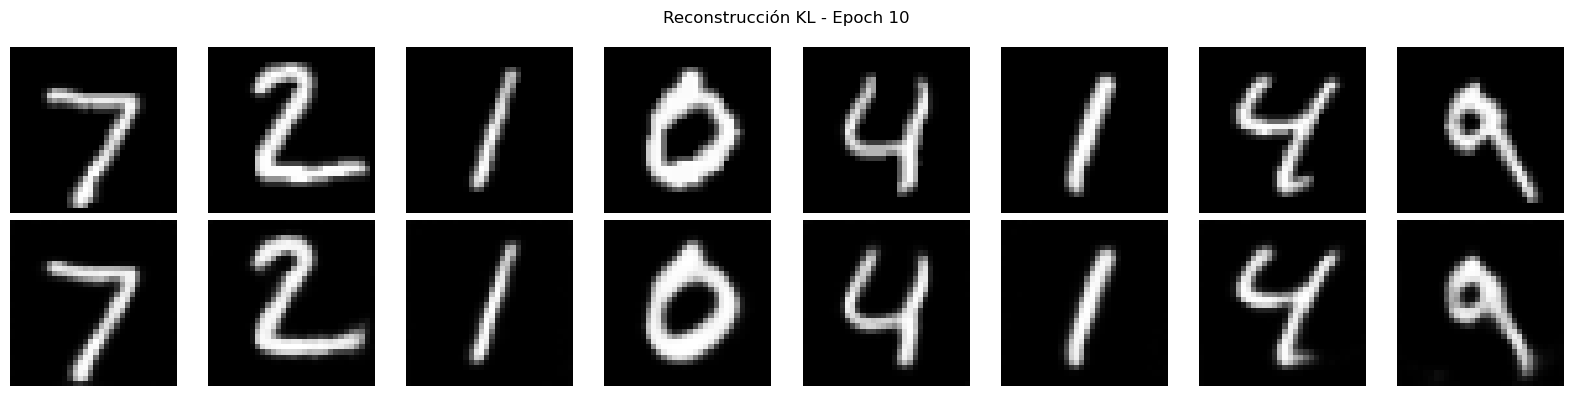

Epoch 11 | loss=1254.2150 recon=1125.1141 KL=129.1009
Epoch 12 | loss=1211.8763 recon=1084.1192 KL=127.7571
Epoch 13 | loss=1193.7749 recon=1066.7377 KL=127.0371
Epoch 14 | loss=1186.0844 recon=1059.3243 KL=126.7601
Epoch 15 | loss=1165.6304 recon=1039.5491 KL=126.0812
Epoch 16 | loss=1139.7107 recon=1013.9358 KL=125.7748
Epoch 17 | loss=1129.4829 recon=1004.1150 KL=125.3680
Epoch 18 | loss=1109.9387 recon=985.1015 KL=124.8372
Epoch 19 | loss=1097.7006 recon=973.1695 KL=124.5311
Epoch 20 | loss=1085.3951 recon=961.0583 KL=124.3369


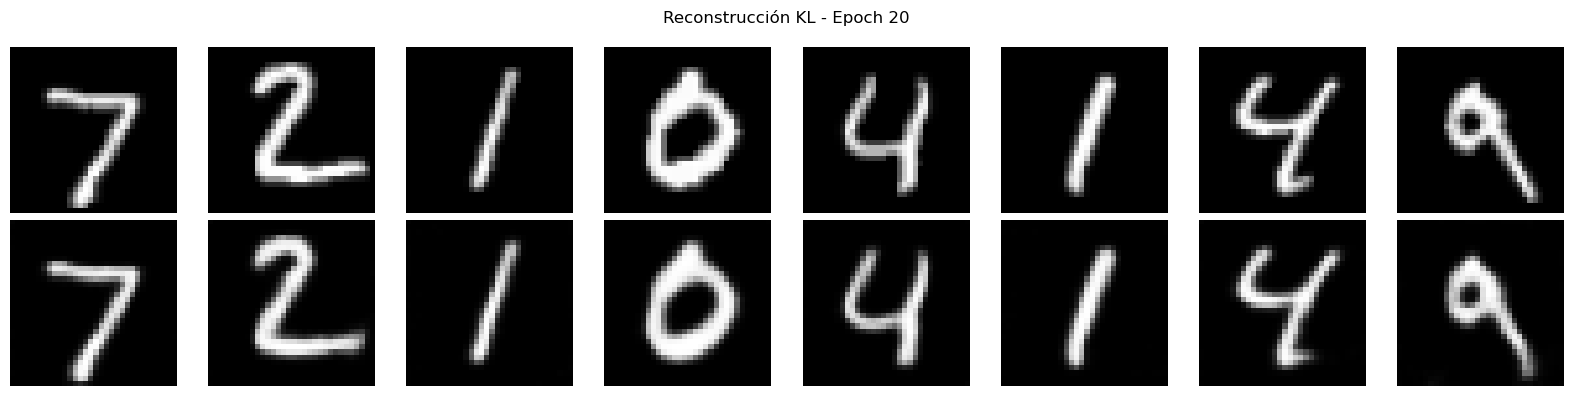

In [26]:
latent_dim = 32
model_mnist_kl = MNISTVAE(latent_dim).to(device)

hist_loss_mnist_kl, hist_rec_mnist_kl, hist_mnist_kl = train_model(model_mnist_kl, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='kl', weight=1.0)

##### Curvas de aprendizaje

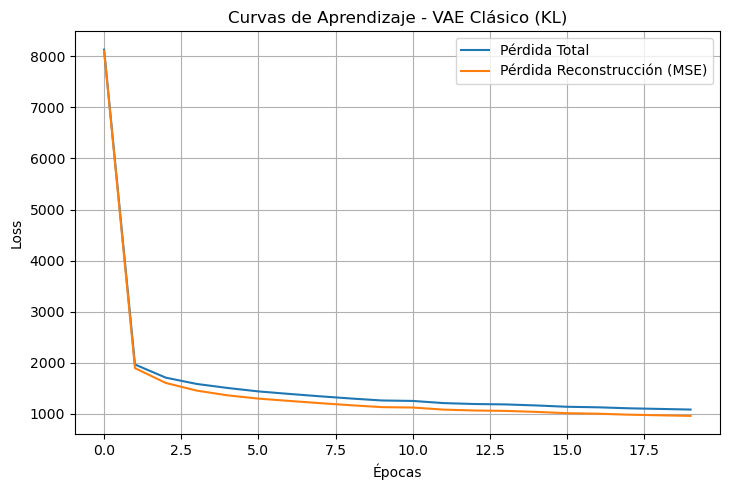

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_loss_mnist_kl, label='Pérdida Total')
plt.plot(hist_rec_mnist_kl, label='Pérdida Reconstrucción (MSE)')
plt.title('Curvas de Aprendizaje - VAE Clásico (KL)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##### Generación de nuevos datos

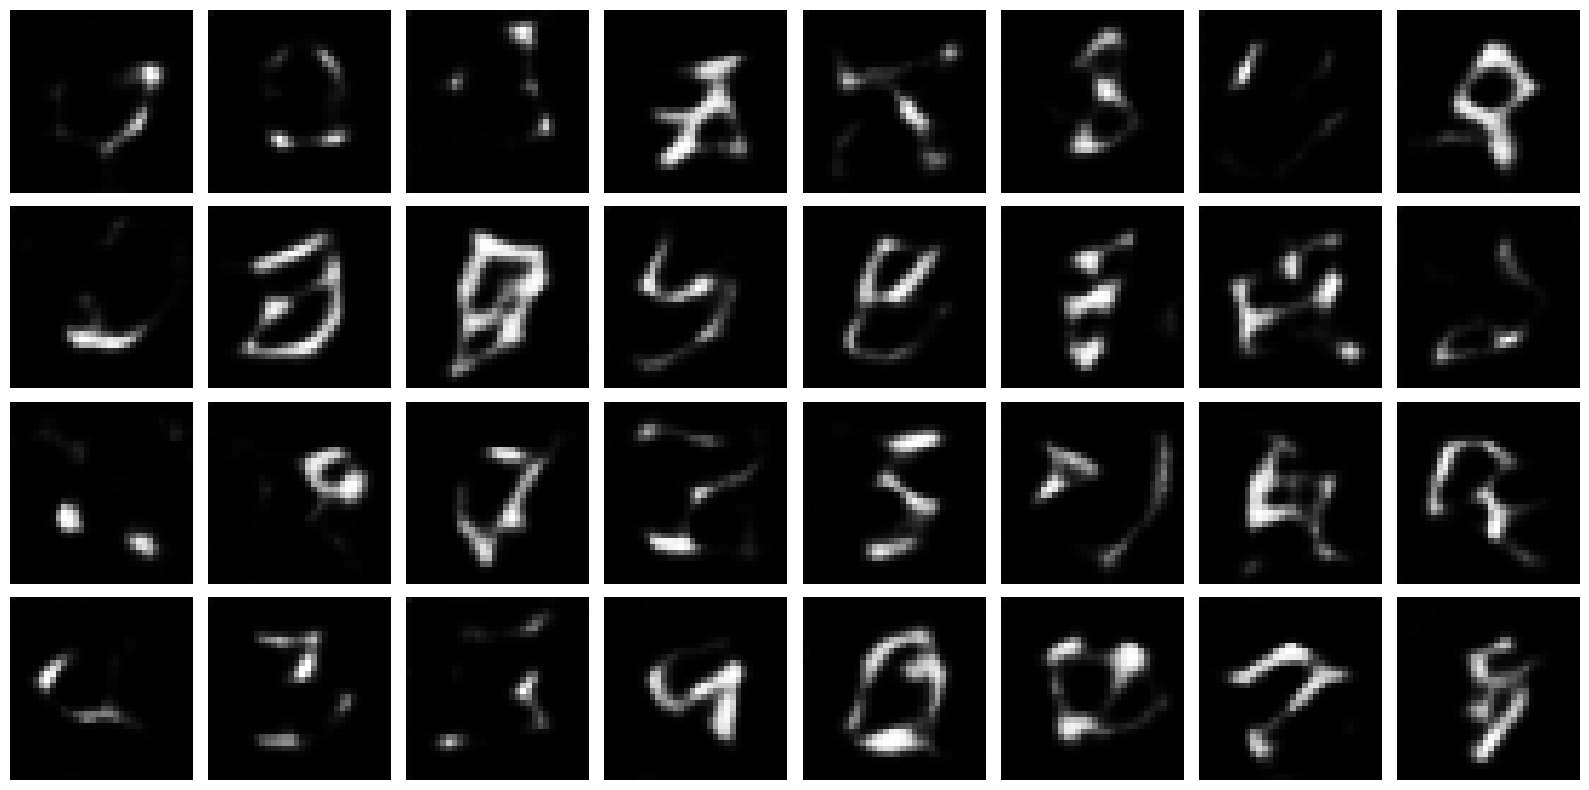

In [28]:
sample_from_prior(model_mnist_kl, n=32, latent_dim=32)

##### Espacio latente (t-SNE)

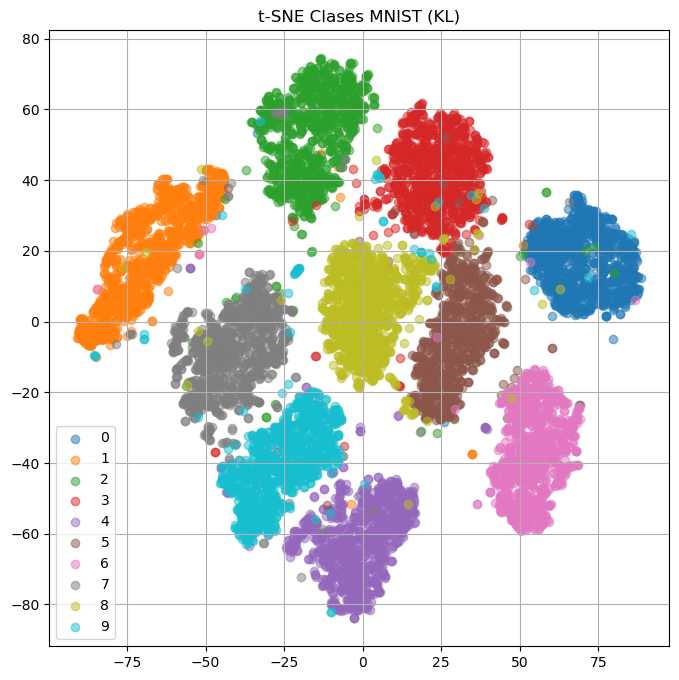

In [29]:
plot_tsne_classes_universal(model_mnist_kl, testloader_mnist, device, title="t-SNE Clases MNIST (KL)")

##### Espacio latente con muestras generadas

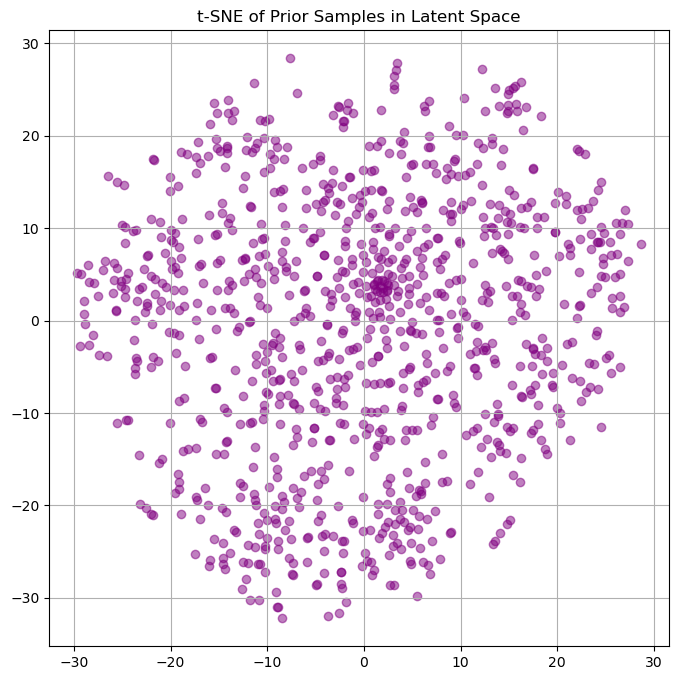

In [30]:
tsne_prior_samples_universal(model_mnist_kl, device, is_cifar=False, latent_dim=32)

##### Espacio latente con recreaciones

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


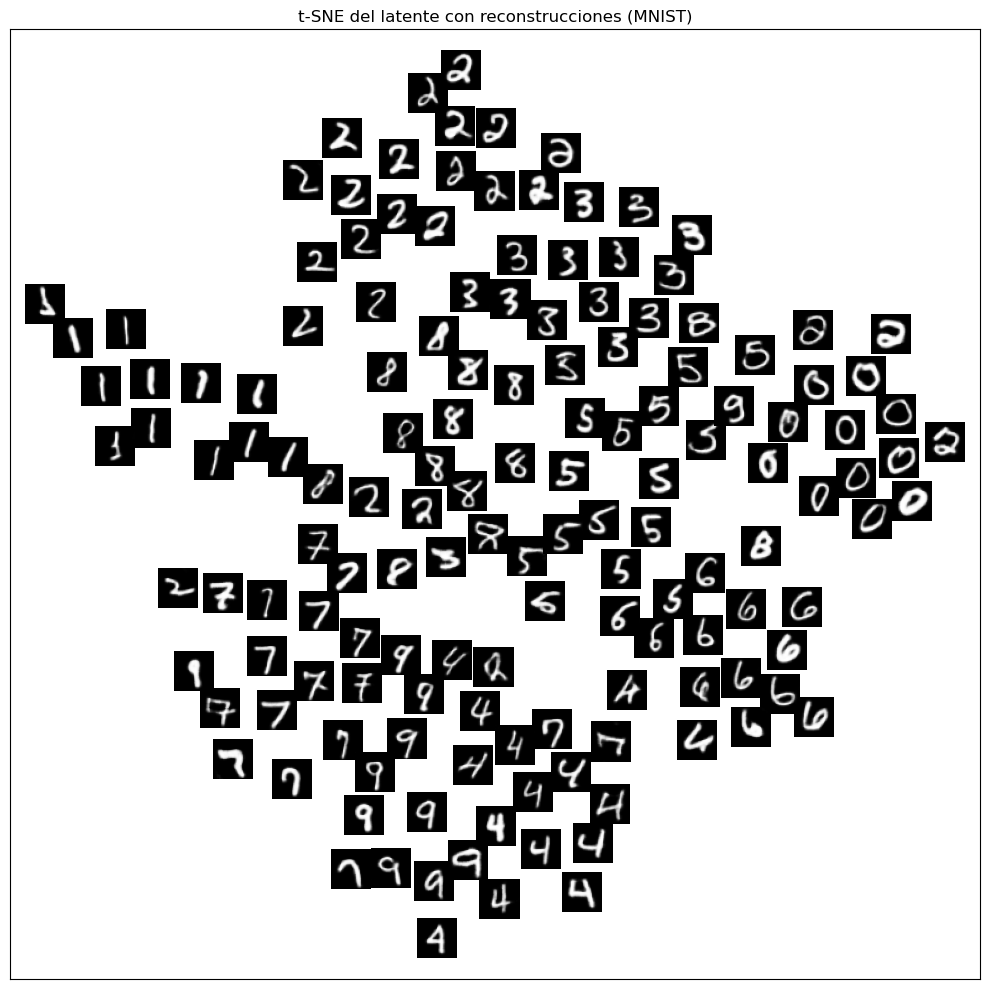

In [31]:
tsne_with_recon_thumbnails_universal(model_mnist_kl, testloader_mnist, device, n_show=150, zoom=0.9)

##### Interpolación

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


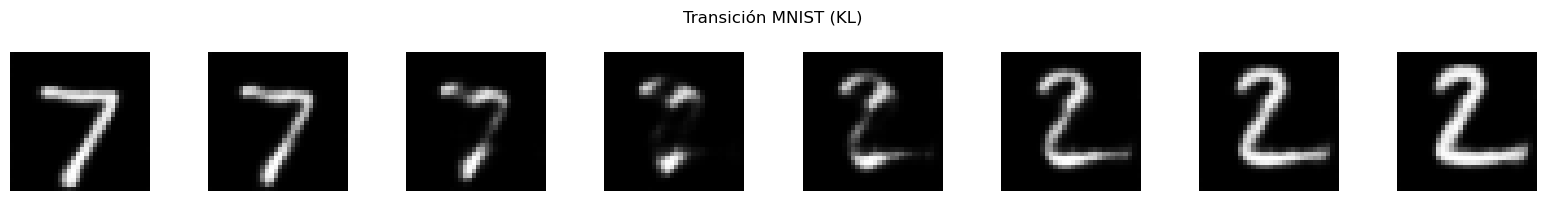

In [32]:
interpolate_universal(model_mnist_kl, testloader_mnist, device, is_cifar=False, title="Transición MNIST (KL)")

### Modelo WAE (MMD)

##### Entrenamiento

Peso=10000

Epoch 01 | loss=9291.9960 recon=9080.3640 MMD=211.6320
Epoch 02 | loss=2033.4302 recon=2002.4174 MMD=31.0128
Epoch 03 | loss=1685.4651 recon=1665.6299 MMD=19.8352
Epoch 04 | loss=1513.7743 recon=1497.5682 MMD=16.2061
Epoch 05 | loss=1410.9431 recon=1397.3792 MMD=13.5639
Epoch 06 | loss=1334.3407 recon=1321.3140 MMD=13.0267
Epoch 07 | loss=1290.8509 recon=1278.4385 MMD=12.4125
Epoch 08 | loss=1250.7058 recon=1238.6229 MMD=12.0829
Epoch 09 | loss=1216.8975 recon=1205.2016 MMD=11.6959
Epoch 10 | loss=1172.8482 recon=1160.8174 MMD=12.0307


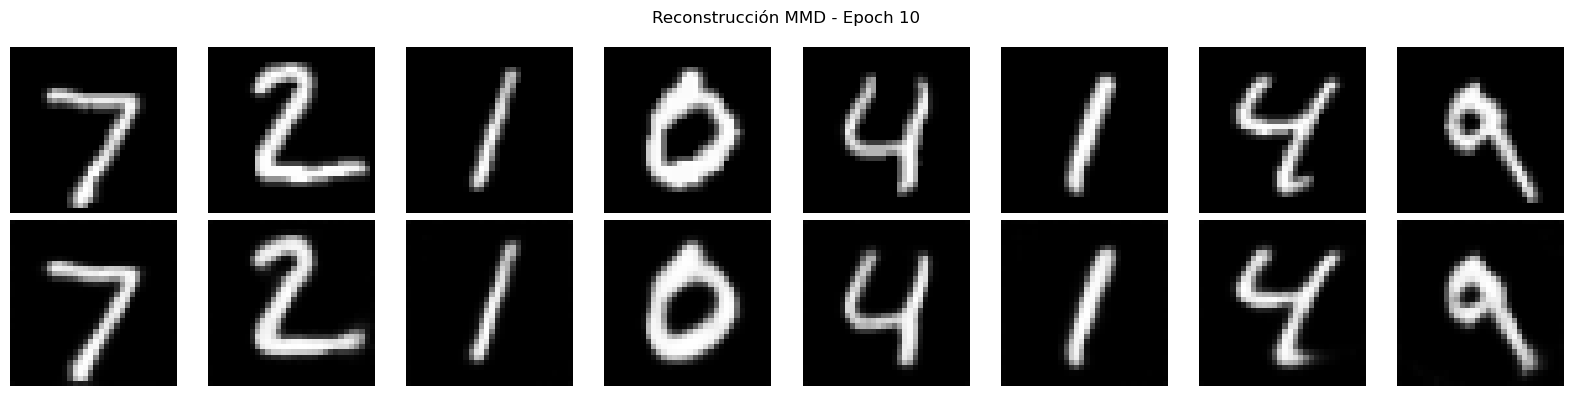

Epoch 11 | loss=1141.7300 recon=1131.3900 MMD=10.3400
Epoch 12 | loss=1126.2014 recon=1115.2520 MMD=10.9494
Epoch 13 | loss=1104.4021 recon=1093.2984 MMD=11.1037
Epoch 14 | loss=1096.3819 recon=1084.5929 MMD=11.7889
Epoch 15 | loss=1061.6995 recon=1051.2422 MMD=10.4573
Epoch 16 | loss=1051.9603 recon=1041.3368 MMD=10.6235
Epoch 17 | loss=1032.3044 recon=1022.3986 MMD=9.9058
Epoch 18 | loss=1011.2248 recon=1001.8832 MMD=9.3416
Epoch 19 | loss=999.9447 recon=990.2120 MMD=9.7327
Epoch 20 | loss=992.8742 recon=982.7474 MMD=10.1268


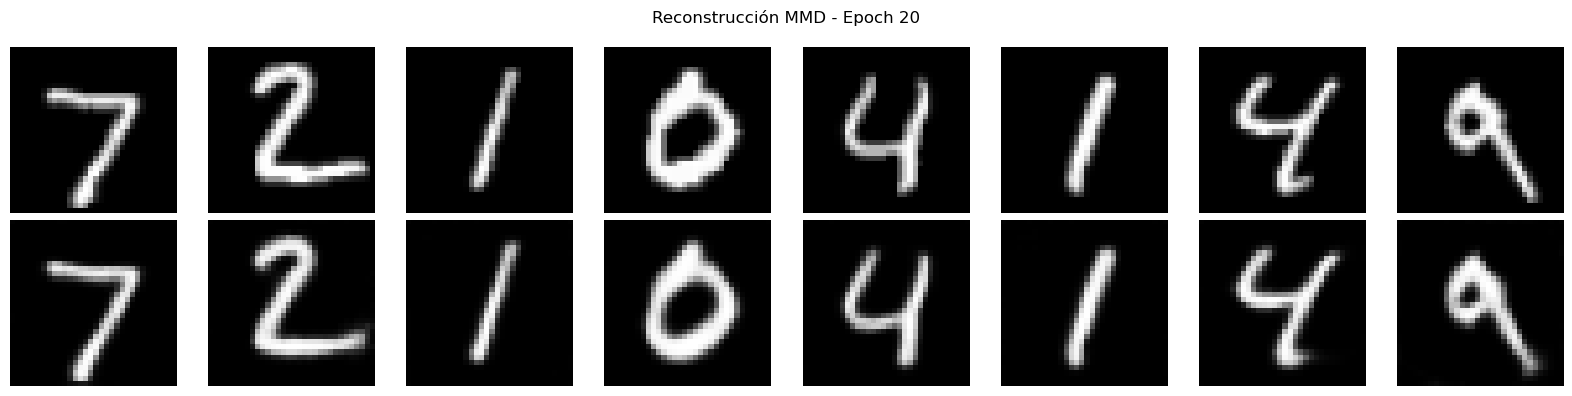

In [33]:
latent_dim = 32
model_mnist_mmd = MNISTWAE(latent_dim).to(device)

hist_loss_mnist_mmd, hist_rec_mnist_mmd, hist_mnist_mmd = train_model(model_mnist_mmd, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='mmd', weight=10000.0)

Peso=1000

Epoch 01 | loss=7529.1973 recon=7444.8338 MMD=84.3635
Epoch 02 | loss=1937.3196 recon=1896.7331 MMD=40.5865
Epoch 03 | loss=1648.4005 recon=1616.7893 MMD=31.6112
Epoch 04 | loss=1492.3257 recon=1469.0348 MMD=23.2909
Epoch 05 | loss=1386.0549 recon=1368.7139 MMD=17.3410
Epoch 06 | loss=1313.3196 recon=1300.1514 MMD=13.1682
Epoch 07 | loss=1253.9479 recon=1243.9132 MMD=10.0347
Epoch 08 | loss=1203.9211 recon=1196.0450 MMD=7.8761
Epoch 09 | loss=1173.3050 recon=1166.7925 MMD=6.5124
Epoch 10 | loss=1134.6325 recon=1129.3297 MMD=5.3028


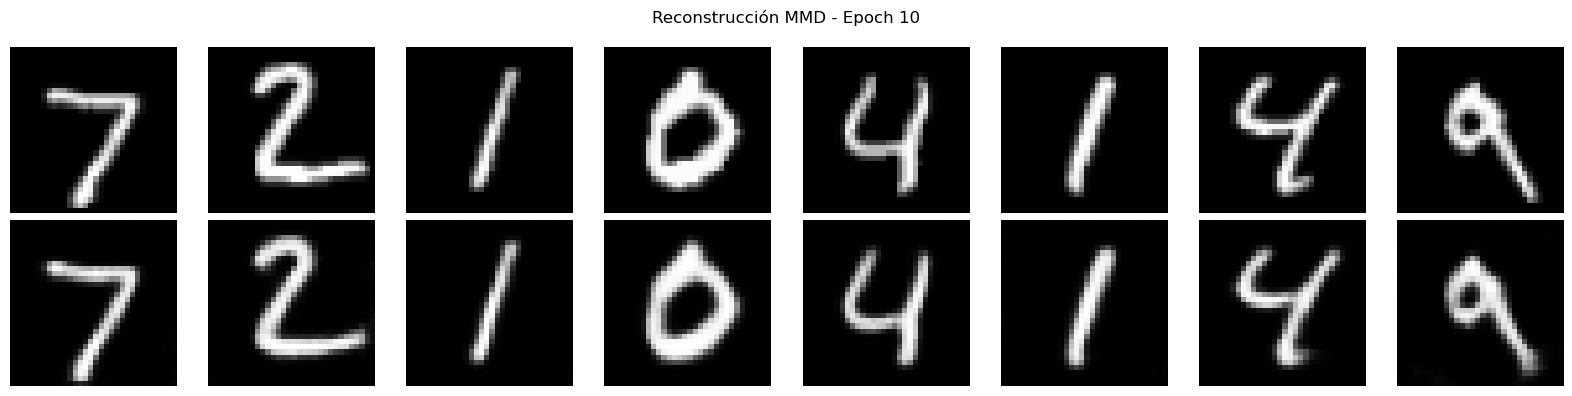

Epoch 11 | loss=1110.1008 recon=1105.5059 MMD=4.5949
Epoch 12 | loss=1080.9830 recon=1076.6880 MMD=4.2950
Epoch 13 | loss=1061.5003 recon=1057.5379 MMD=3.9624
Epoch 14 | loss=1037.7661 recon=1034.1817 MMD=3.5844
Epoch 15 | loss=1020.3034 recon=1016.7489 MMD=3.5545
Epoch 16 | loss=996.1887 recon=992.9720 MMD=3.2167
Epoch 17 | loss=990.6522 recon=987.3532 MMD=3.2989
Epoch 18 | loss=973.1285 recon=970.0133 MMD=3.1152
Epoch 19 | loss=951.4278 recon=948.6154 MMD=2.8124
Epoch 20 | loss=946.0751 recon=943.1419 MMD=2.9332


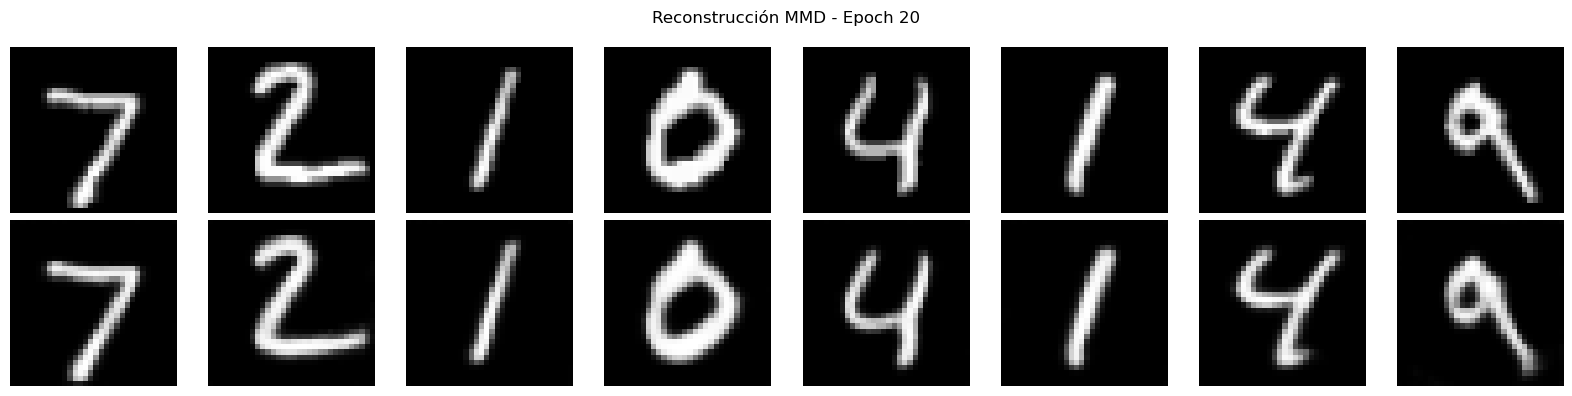

In [17]:
latent_dim = 32
model_mnist_mmd = MNISTWAE(latent_dim).to(device)

hist_loss_mnist_mmd, hist_rec_mnist_mmd, hist_mnist_mmd = train_model(model_mnist_mmd, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='mmd', weight=1000.0)

Peso=5000

Epoch 01 | loss=9186.2142 recon=9022.9797 MMD=163.2345
Epoch 02 | loss=2017.0886 recon=1981.8565 MMD=35.2321
Epoch 03 | loss=1684.1347 recon=1663.9873 MMD=20.1473
Epoch 04 | loss=1510.7975 recon=1497.3555 MMD=13.4420
Epoch 05 | loss=1389.8229 recon=1379.8545 MMD=9.9684
Epoch 06 | loss=1330.0989 recon=1320.6597 MMD=9.4391
Epoch 07 | loss=1260.1922 recon=1252.0403 MMD=8.1519
Epoch 08 | loss=1212.8203 recon=1205.4117 MMD=7.4086
Epoch 09 | loss=1169.3956 recon=1161.9644 MMD=7.4312
Epoch 10 | loss=1139.5753 recon=1132.1711 MMD=7.4042


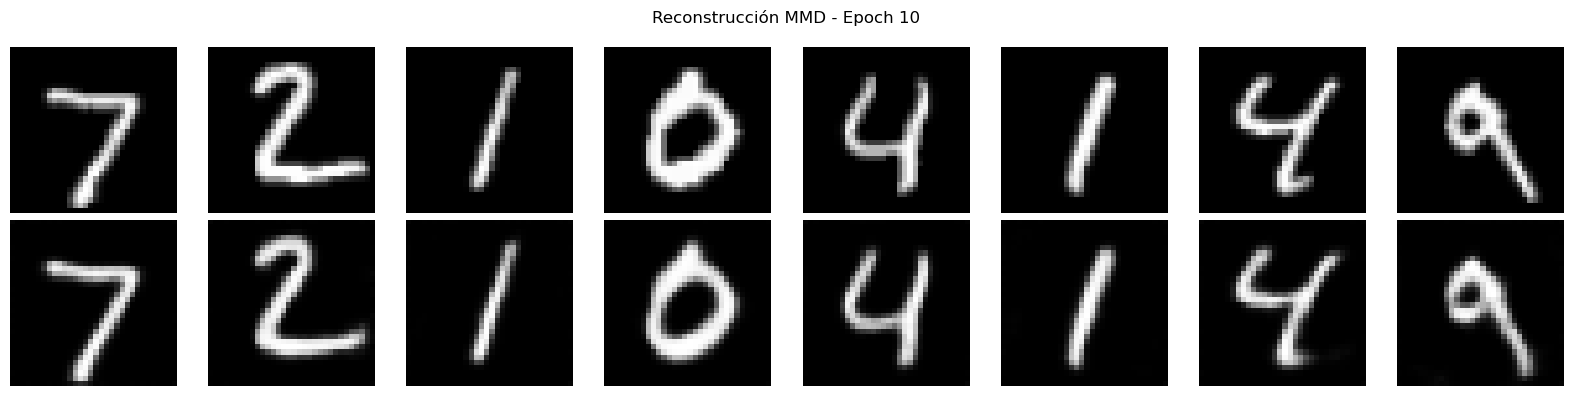

Epoch 11 | loss=1133.8187 recon=1126.2194 MMD=7.5994
Epoch 12 | loss=1095.8080 recon=1088.9605 MMD=6.8475
Epoch 13 | loss=1076.2544 recon=1069.1860 MMD=7.0683
Epoch 14 | loss=1046.6324 recon=1039.8982 MMD=6.7342
Epoch 15 | loss=1025.5110 recon=1018.6245 MMD=6.8864
Epoch 16 | loss=1007.3371 recon=1001.1463 MMD=6.1907
Epoch 17 | loss=999.9738 recon=993.5767 MMD=6.3971
Epoch 18 | loss=985.3104 recon=979.1713 MMD=6.1391
Epoch 19 | loss=981.9656 recon=975.3451 MMD=6.6205
Epoch 20 | loss=961.7626 recon=955.4771 MMD=6.2855


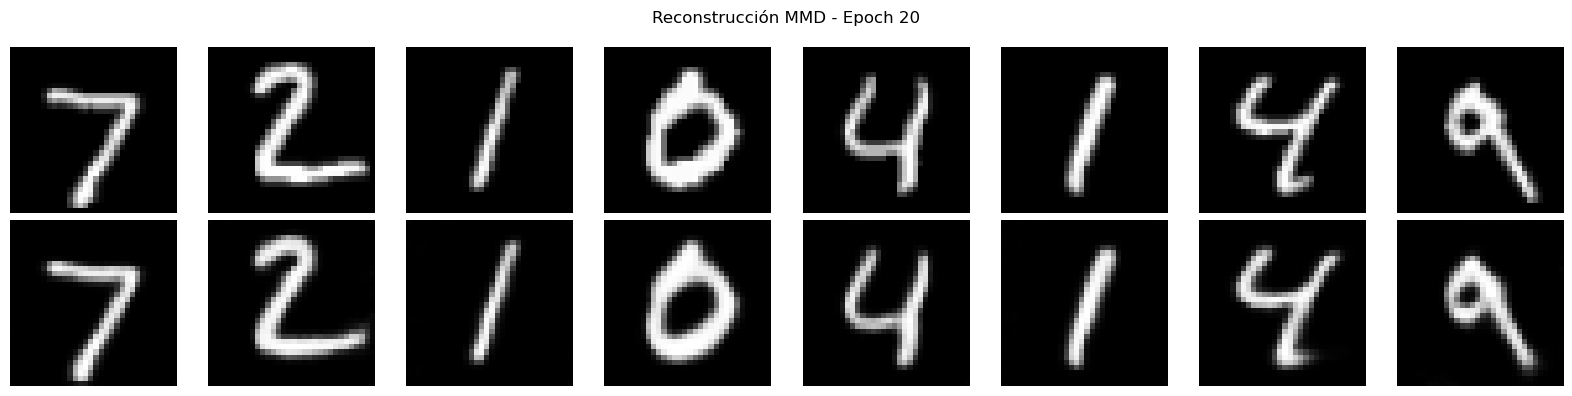

In [19]:
latent_dim = 32
model_mnist_mmd = MNISTWAE(latent_dim).to(device)

hist_loss_mnist_mmd, hist_rec_mnist_mmd, hist_mnist_mmd = train_model(model_mnist_mmd, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='mmd', weight=5000.0)

Peso=20000

Epoch 01 | loss=8204.0196 recon=7971.0422 MMD=232.9773
Epoch 02 | loss=2031.3192 recon=1993.7774 MMD=37.5418
Epoch 03 | loss=1719.4923 recon=1689.5831 MMD=29.9092
Epoch 04 | loss=1547.6020 recon=1523.5707 MMD=24.0313
Epoch 05 | loss=1447.0618 recon=1424.6626 MMD=22.3992
Epoch 06 | loss=1369.9630 recon=1350.1134 MMD=19.8496
Epoch 07 | loss=1326.8005 recon=1307.4959 MMD=19.3046
Epoch 08 | loss=1262.6728 recon=1244.8533 MMD=17.8195
Epoch 09 | loss=1223.8976 recon=1206.5914 MMD=17.3062
Epoch 10 | loss=1211.1133 recon=1193.6872 MMD=17.4261


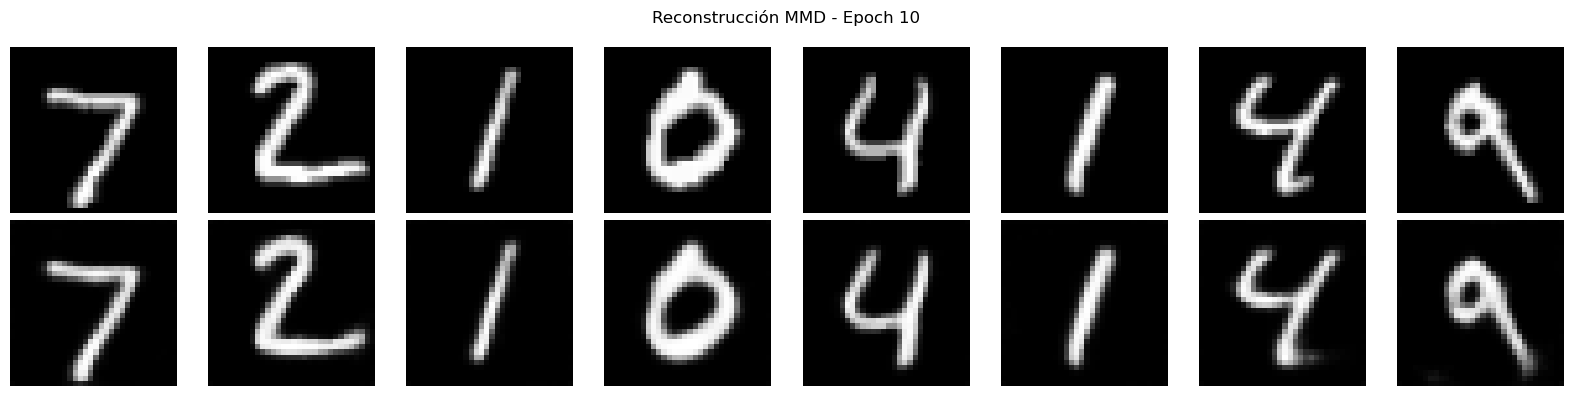

Epoch 11 | loss=1160.3966 recon=1145.5619 MMD=14.8347
Epoch 12 | loss=1158.0470 recon=1141.2319 MMD=16.8152
Epoch 13 | loss=1124.4199 recon=1107.8093 MMD=16.6105
Epoch 14 | loss=1103.3459 recon=1088.1107 MMD=15.2352
Epoch 15 | loss=1090.8676 recon=1074.2520 MMD=16.6156
Epoch 16 | loss=1066.8779 recon=1053.1183 MMD=13.7596
Epoch 17 | loss=1041.6631 recon=1027.9958 MMD=13.6673
Epoch 18 | loss=1038.6524 recon=1022.9558 MMD=15.6967
Epoch 19 | loss=1018.8073 recon=1004.3955 MMD=14.4117
Epoch 20 | loss=999.9241 recon=987.1235 MMD=12.8006


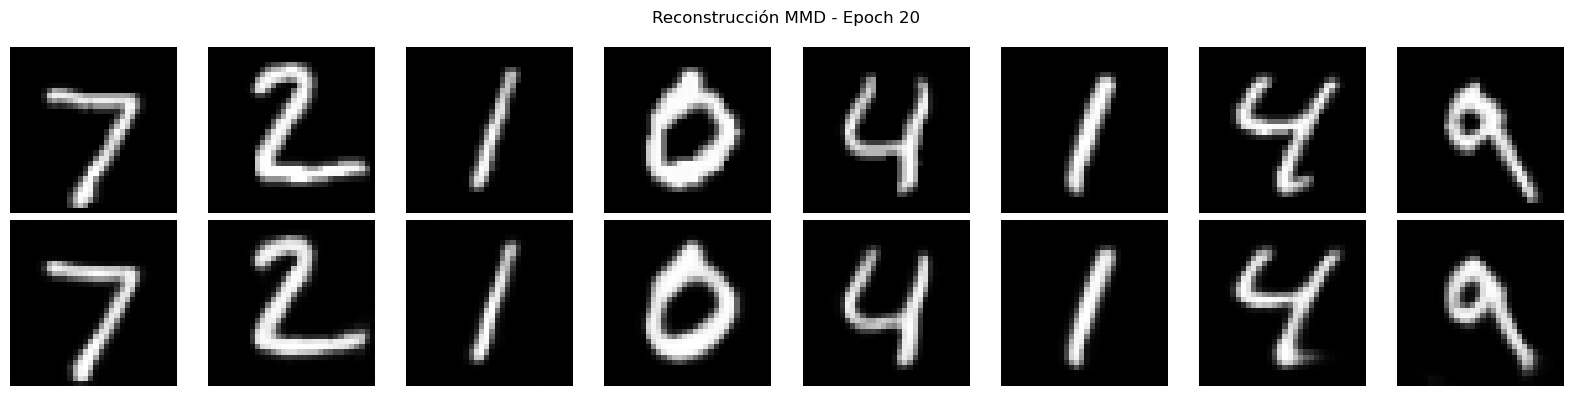

In [20]:
latent_dim = 32
model_mnist_mmd = MNISTWAE(latent_dim).to(device)

hist_loss_mnist_mmd, hist_rec_mnist_mmd, hist_mnist_mmd = train_model(model_mnist_mmd, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='mmd', weight=20000.0)

Peso=50000

Epoch 01 | loss=9634.6506 recon=9275.2029 MMD=359.4478
Epoch 02 | loss=2167.0548 recon=2081.2478 MMD=85.8070
Epoch 03 | loss=1820.9109 recon=1760.7341 MMD=60.1768
Epoch 04 | loss=1630.9914 recon=1578.4122 MMD=52.5792
Epoch 05 | loss=1523.2551 recon=1479.1739 MMD=44.0812
Epoch 06 | loss=1440.5467 recon=1400.1969 MMD=40.3498
Epoch 07 | loss=1362.0639 recon=1329.2035 MMD=32.8604
Epoch 08 | loss=1327.1395 recon=1296.0390 MMD=31.1005
Epoch 09 | loss=1281.1495 recon=1256.2266 MMD=24.9229
Epoch 10 | loss=1251.8165 recon=1227.2134 MMD=24.6031


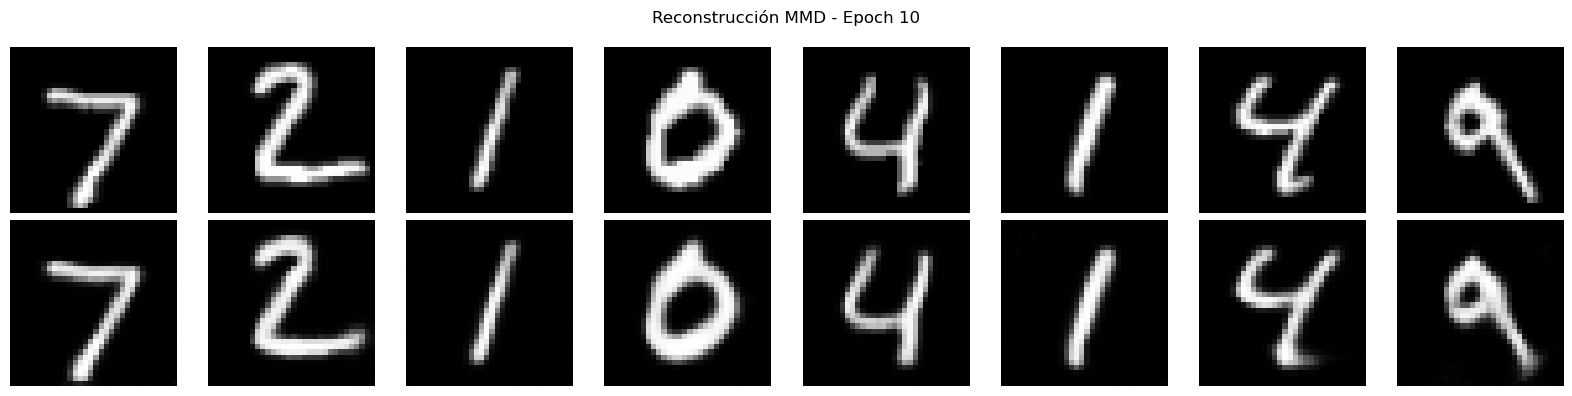

Epoch 11 | loss=1225.8070 recon=1199.7474 MMD=26.0596
Epoch 12 | loss=1204.2536 recon=1180.2170 MMD=24.0366
Epoch 13 | loss=1171.4764 recon=1149.1185 MMD=22.3579
Epoch 14 | loss=1157.2589 recon=1132.8939 MMD=24.3650
Epoch 15 | loss=1133.2113 recon=1111.9749 MMD=21.2365
Epoch 16 | loss=1107.4594 recon=1088.5918 MMD=18.8675
Epoch 17 | loss=1107.6052 recon=1085.0119 MMD=22.5933
Epoch 18 | loss=1095.0396 recon=1070.5877 MMD=24.4518
Epoch 19 | loss=1067.6902 recon=1047.9367 MMD=19.7535
Epoch 20 | loss=1060.9742 recon=1041.0448 MMD=19.9294


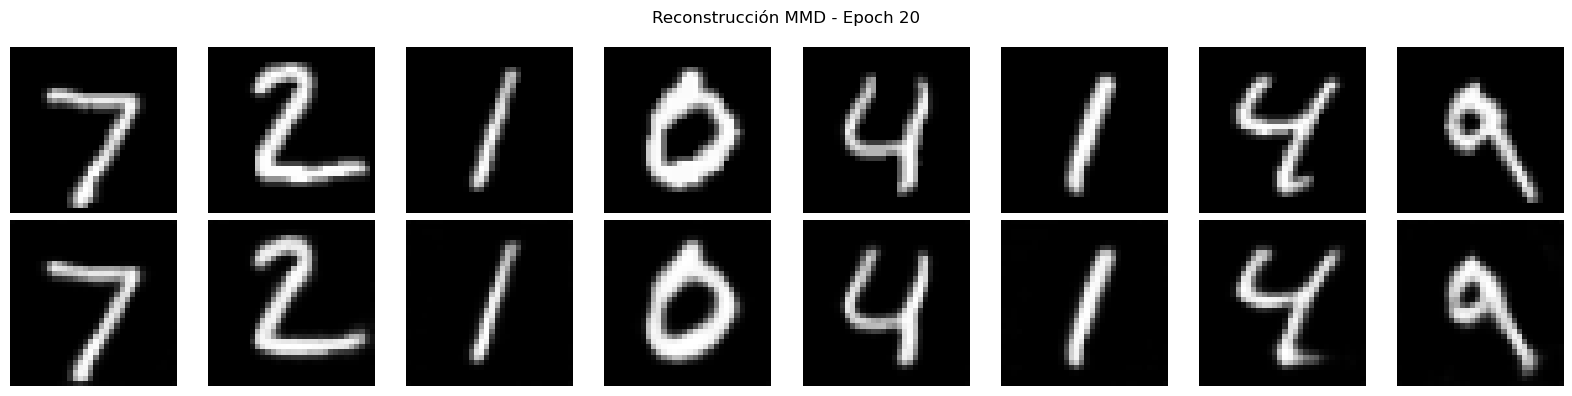

In [18]:
latent_dim = 32
model_mnist_mmd = MNISTWAE(latent_dim).to(device)

hist_loss_mnist_mmd, hist_rec_mnist_mmd, hist_mnist_mmd = train_model(model_mnist_mmd, trainloader_mnist, testloader_mnist, device, epochs=20, loss_type='mmd', weight=50000.0)

##### Curvas de aprendizaje

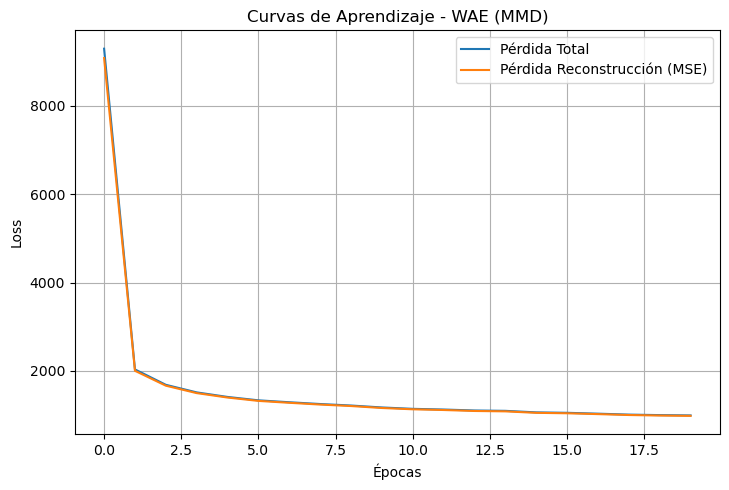

In [34]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_loss_mnist_mmd, label='Pérdida Total')
plt.plot(hist_rec_mnist_mmd, label='Pérdida Reconstrucción (MSE)')
plt.title('Curvas de Aprendizaje - WAE (MMD)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##### Generación de nuevos datos

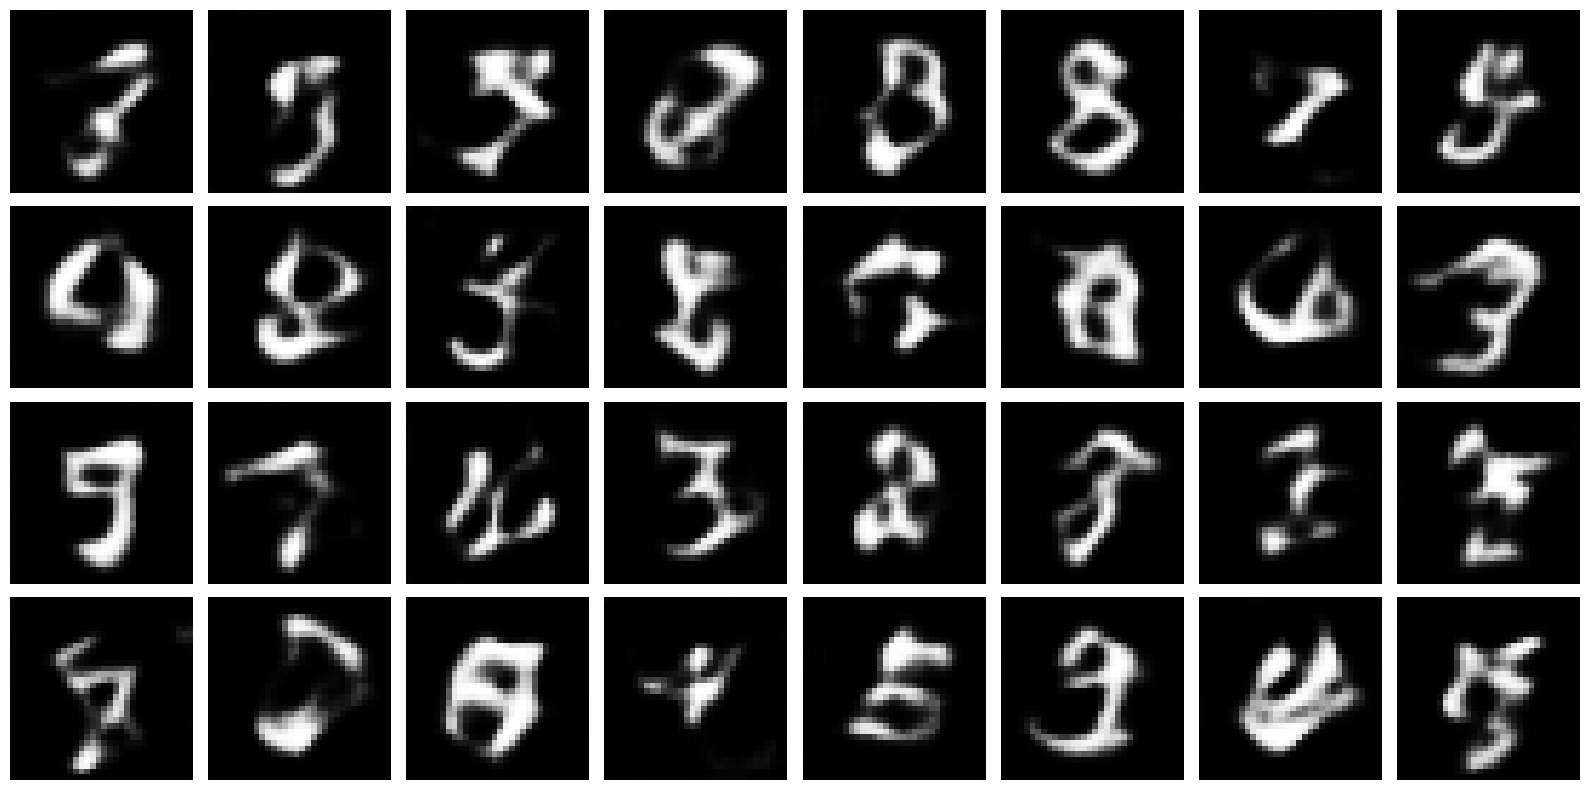

In [35]:
sample_from_prior(model_mnist_mmd, n=32, latent_dim=32)

##### Espacio latente (t-SNE)

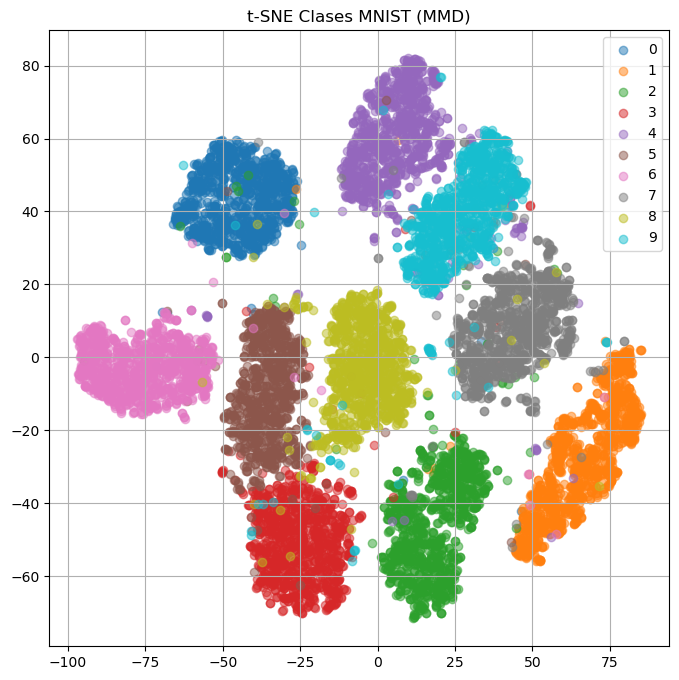

In [36]:
plot_tsne_classes_universal(model_mnist_mmd, testloader_mnist, device, title="t-SNE Clases MNIST (MMD)")

##### Espacio latente con muestras generadas

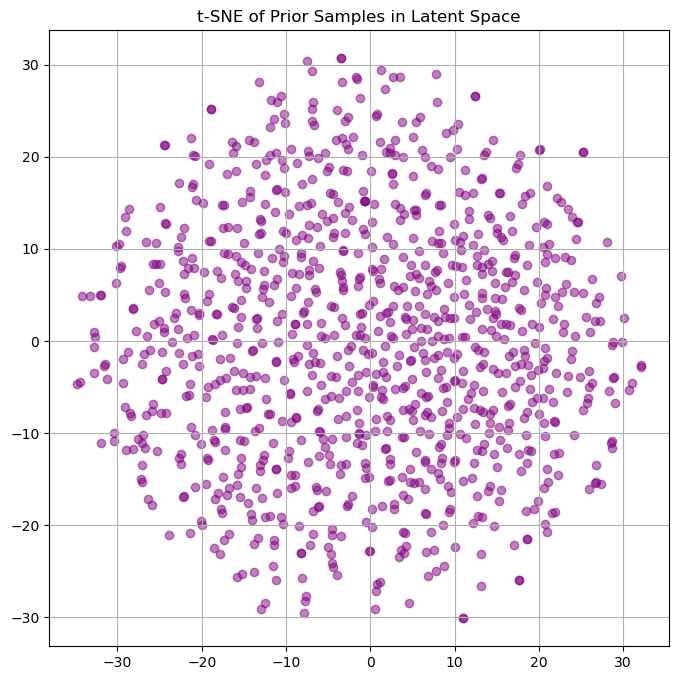

In [37]:
tsne_prior_samples_universal(model_mnist_mmd, device, is_cifar=False, latent_dim=32)

##### Espacio latente con recreaciones

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


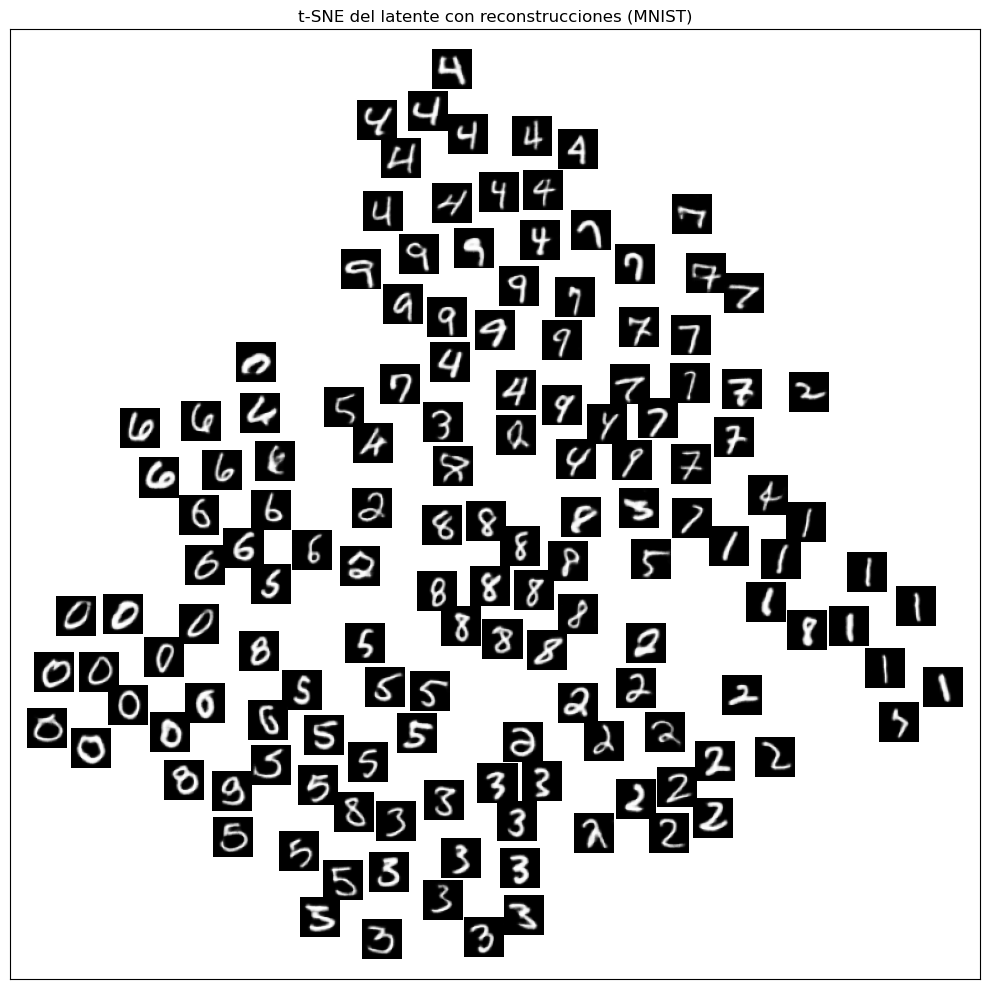

In [38]:
tsne_with_recon_thumbnails_universal(model_mnist_mmd, testloader_mnist, device, n_show=150, zoom=0.9)

##### Interpolación

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


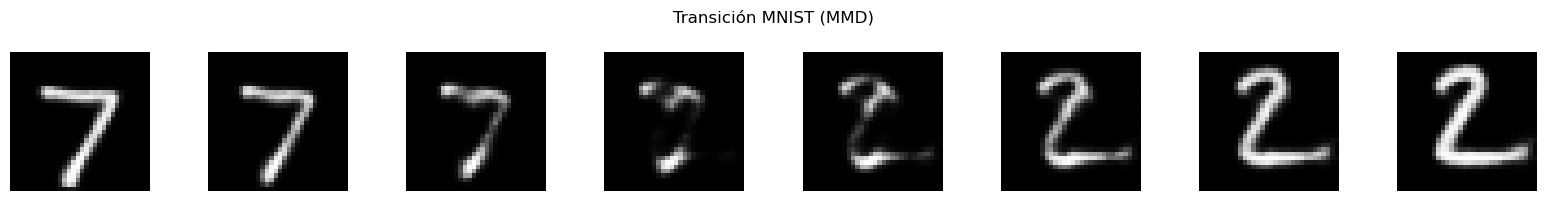

In [39]:
interpolate_universal(model_mnist_mmd, testloader_mnist, device, is_cifar=False, title="Transición MNIST (MMD)")

## CIFAR-10

#### Carga de datos

In [ ]:
# ----------------------------
# Data
# ----------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

cifar_train = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
cifar_test  = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

classes = ('plane','car','bird','cat','deer','dog','frog','horse','ship','truck')

# Usamos solo 4 clases
keep_classes = [0, 1, 2, 3]
def filter_cifar(dataset, keep):
    idx = [i for i, y in enumerate(dataset.targets) if y in keep]
    dataset.data = dataset.data[idx]
    dataset.targets = [dataset.targets[i] for i in idx]
    return dataset

cifar_train = filter_cifar(cifar_train, keep_classes)
cifar_test  = filter_cifar(cifar_test, keep_classes)


batch_size = 128
trainloader_cifar = DataLoader(cifar_train, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
testloader_cifar  = DataLoader(cifar_test,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

#### Modelo CIFAR-10

In [ ]:
# ----------------------------
# Model
# ----------------------------
class CIFAREncoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),  # 16x16
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(32, 64, 4, 2, 1), # 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1), # 4x4
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
        )
        self.fc_mu = nn.Linear(128*4*4, latent_dim)
        self.fc_logvar = nn.Linear(128*4*4, latent_dim)

    def forward(self, x):
        h = self.net(x).view(x.size(0), -1)
        return self.fc_mu(h), self.fc_logvar(h)

class CIFARDecoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128*4*4)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),
            

            nn.ConvTranspose2d(64, 32, 4, 2, 1),   # 16x16
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),

            nn.ConvTranspose2d(32, 3, 4, 2, 1),    # 32x32
        )

    def forward(self, z):
        h = self.fc(z).view(z.size(0), 128, 4, 4)
        x_logits = self.net(h)
        return torch.tanh(x_logits)

class CIFARVAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.enc = CIFAREncoder(latent_dim)
        self.dec = CIFARDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.enc(x)
        z = self.reparameterize(mu, logvar)
        recon = self.dec(z)
        return recon, mu, logvar
    

class CIFAREncoderWAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),   # 16x16
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(32, 64, 4, 2, 1),  # 8x8
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1), # 4x4
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
        )
        self.fc_z = nn.Linear(128*4*4, latent_dim)  # solo z, sin mu ni logvar

    def forward(self, x):
        h = self.net(x).view(x.size(0), -1)
        return self.fc_z(h)


class CIFARWAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.enc = CIFAREncoderWAE(latent_dim)
        self.dec = CIFARDecoder(latent_dim)

    def forward(self, x):
        z = self.enc(x)
        recon = self.dec(z)
        return recon, z  # sin mu ni logvar

### VAE clásico (KL)

##### Entrenamiento

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | loss=44782.1843 recon=44740.9752 KL=3044.3023
Epoch 02 | loss=20535.2204 recon=20446.7967 KL=755.8964
Epoch 03 | loss=15934.4364 recon=15793.5575 KL=720.7719
Epoch 04 | loss=13438.1208 recon=13251.7393 KL=679.6725
Epoch 05 | loss=11675.5030 recon=11443.6020 KL=657.2290
Epoch 06 | loss=10664.8159 recon=10391.0596 KL=634.7653
Epoch 07 | loss=9927.0410 recon=9614.6663 KL=612.8203
Epoch 08 | loss=9407.3252 recon=9056.1398 KL=597.1414
Epoch 09 | loss=9157.4001 recon=8773.8228 KL=575.2105
Epoch 10 | loss=8868.7792 recon=8457.4788 KL=551.8871


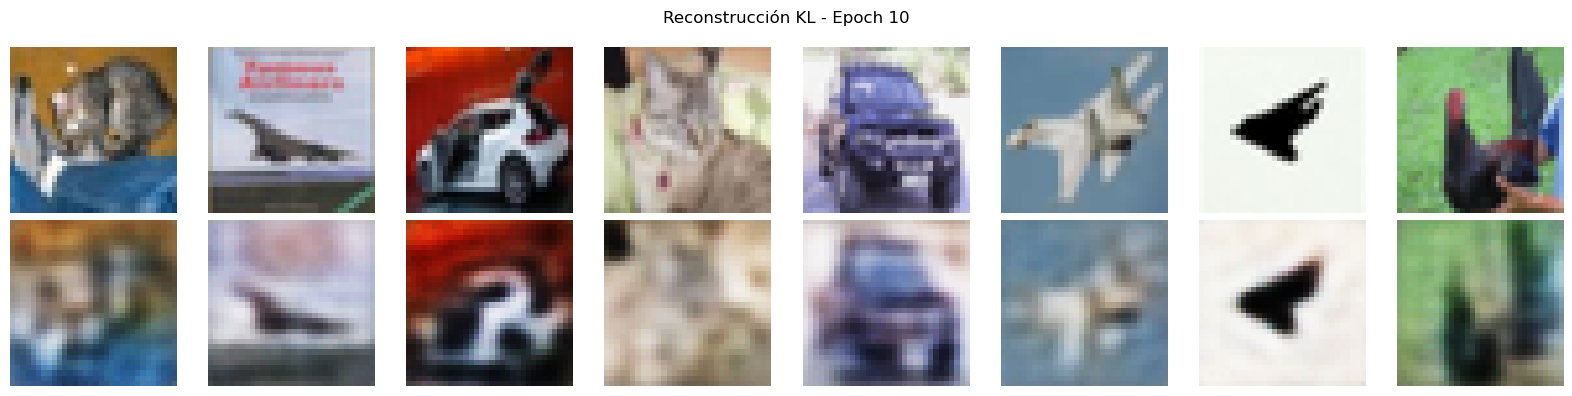

Epoch 11 | loss=8831.4314 recon=8389.8569 KL=535.9642
Epoch 12 | loss=8688.5984 recon=8222.9594 KL=516.1088
Epoch 13 | loss=8684.6283 recon=8197.8549 KL=497.5736
Epoch 14 | loss=8759.4778 recon=8268.3764 KL=491.1014
Epoch 15 | loss=8581.7978 recon=8100.6818 KL=481.1160
Epoch 16 | loss=8476.4177 recon=8001.6646 KL=474.7530
Epoch 17 | loss=8506.4947 recon=8034.7730 KL=471.7216
Epoch 18 | loss=8382.6551 recon=7917.9985 KL=464.6567
Epoch 19 | loss=8330.8846 recon=7870.5901 KL=460.2946
Epoch 20 | loss=8257.6324 recon=7801.3152 KL=456.3172


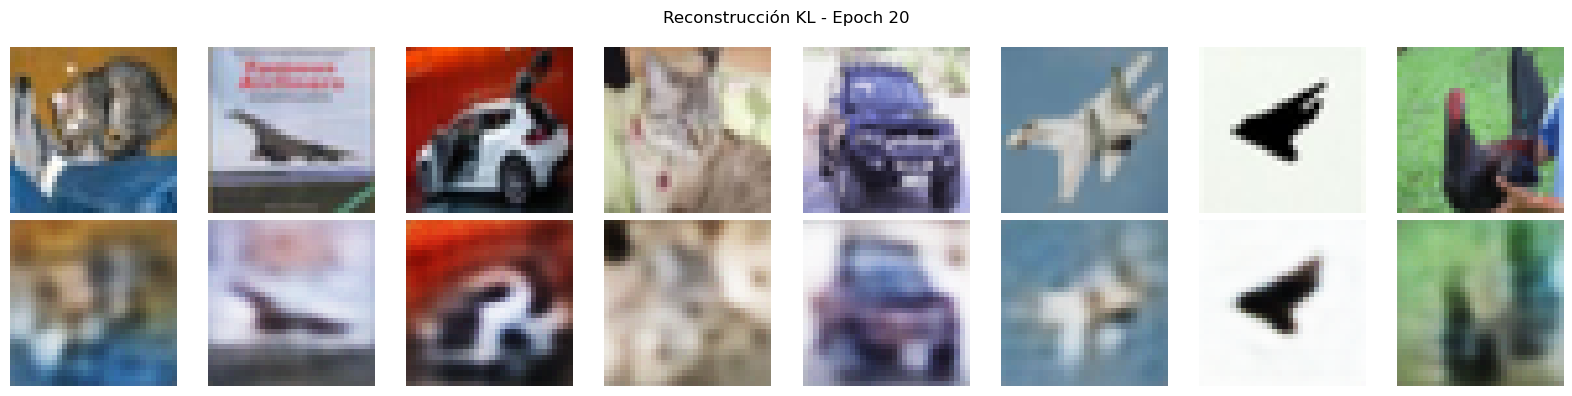

Epoch 21 | loss=8241.7394 recon=7787.9264 KL=453.8130
Epoch 22 | loss=8216.8615 recon=7766.9010 KL=449.9605
Epoch 23 | loss=8186.0973 recon=7737.0819 KL=449.0153
Epoch 24 | loss=8086.0204 recon=7640.5177 KL=445.5027
Epoch 25 | loss=8090.9150 recon=7646.9852 KL=443.9298
Epoch 26 | loss=8042.2098 recon=7600.7796 KL=441.4302
Epoch 27 | loss=8046.4262 recon=7605.3143 KL=441.1119
Epoch 28 | loss=8063.7918 recon=7625.2848 KL=438.5069
Epoch 29 | loss=7928.3235 recon=7491.1873 KL=437.1362
Epoch 30 | loss=7940.5280 recon=7503.2388 KL=437.2892


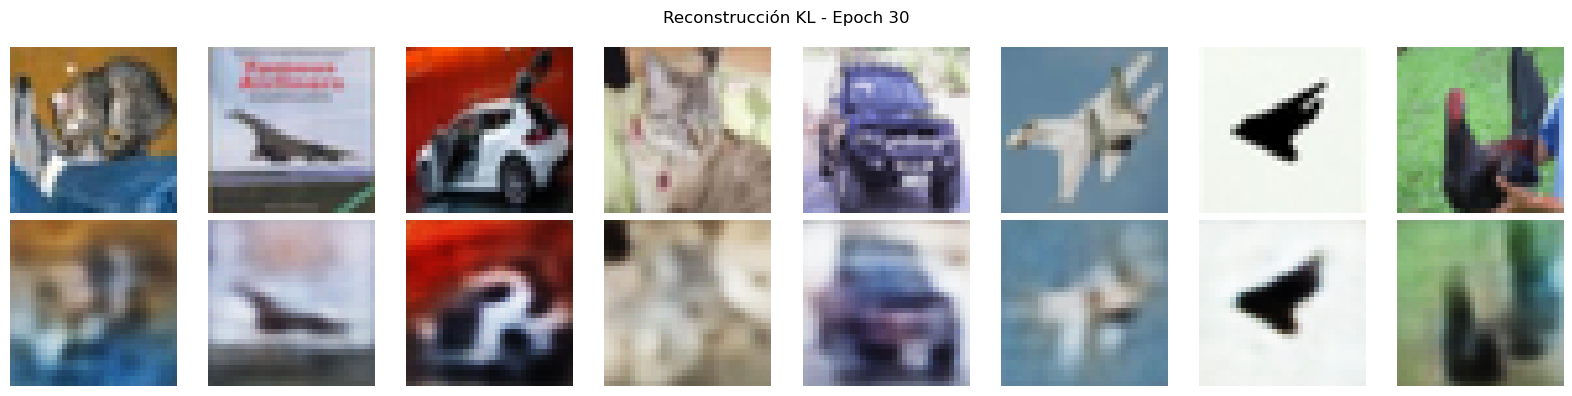

Epoch 31 | loss=7936.7008 recon=7500.5859 KL=436.1150
Epoch 32 | loss=7844.1421 recon=7409.3656 KL=434.7765
Epoch 33 | loss=7939.0973 recon=7505.1507 KL=433.9466
Epoch 34 | loss=7833.9492 recon=7400.1965 KL=433.7527
Epoch 35 | loss=7764.3788 recon=7331.9735 KL=432.4053
Epoch 36 | loss=7803.6699 recon=7372.6558 KL=431.0141
Epoch 37 | loss=7769.2423 recon=7338.2216 KL=431.0208
Epoch 38 | loss=7713.4401 recon=7284.1319 KL=429.3082
Epoch 39 | loss=7687.9946 recon=7259.4228 KL=428.5718
Epoch 40 | loss=7595.7612 recon=7167.8250 KL=427.9362


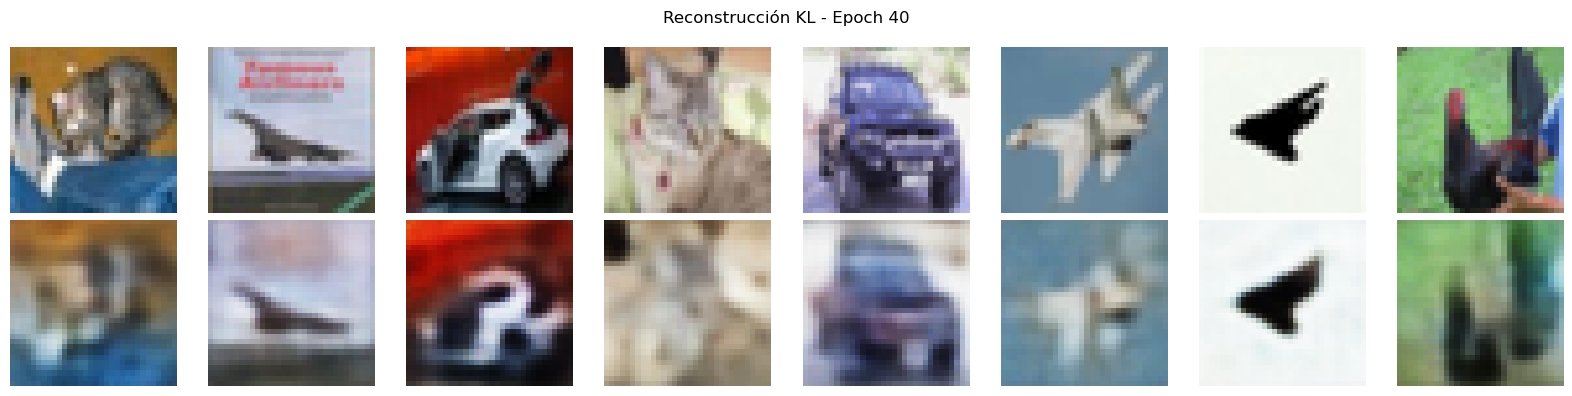

Epoch 41 | loss=7634.2519 recon=7207.1271 KL=427.1248
Epoch 42 | loss=7611.7245 recon=7185.4495 KL=426.2751
Epoch 43 | loss=7607.0244 recon=7180.7148 KL=426.3096
Epoch 44 | loss=7598.3287 recon=7172.5610 KL=425.7677
Epoch 45 | loss=7577.0484 recon=7151.2302 KL=425.8182
Epoch 46 | loss=7575.0068 recon=7149.1692 KL=425.8376
Epoch 47 | loss=7527.8182 recon=7103.2025 KL=424.6156
Epoch 48 | loss=7487.8206 recon=7062.9442 KL=424.8763
Epoch 49 | loss=7533.6453 recon=7108.9932 KL=424.6522
Epoch 50 | loss=7528.9004 recon=7104.9632 KL=423.9372


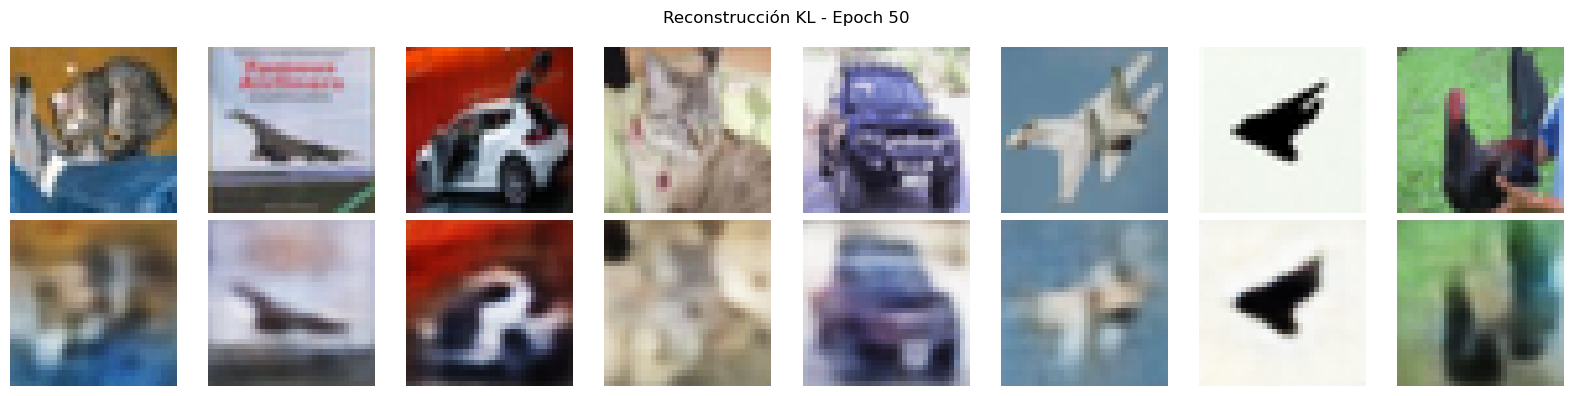

In [10]:
latent_dim = 128
model_cifar_kl = CIFARVAE(latent_dim).to(device)

hist_loss_cifar_kl, hist_rec_cifar_kl, hist_cifar_kl = train_model(model_cifar_kl, trainloader_cifar, testloader_cifar, device, epochs=50, loss_type='kl', weight=1.0)

##### Curvas de aprendizaje

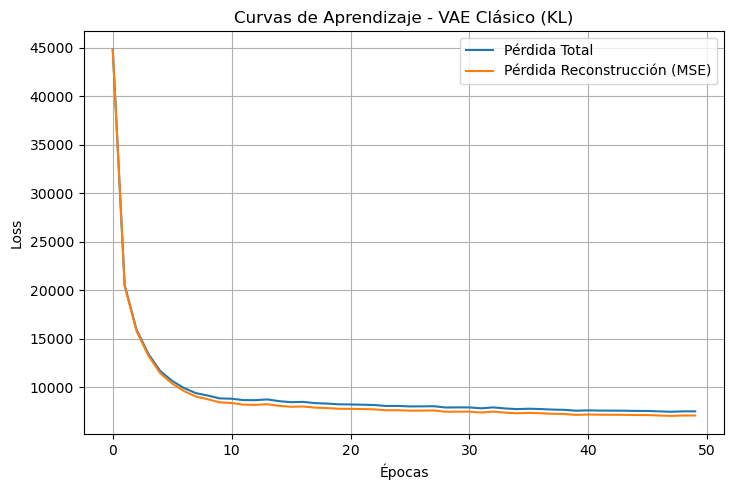

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(hist_loss_cifar_kl, label='Pérdida Total')
plt.plot(hist_rec_cifar_kl, label='Pérdida Reconstrucción (MSE)')
plt.title('Curvas de Aprendizaje - VAE Clásico (KL)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##### Generación de nuevos datos

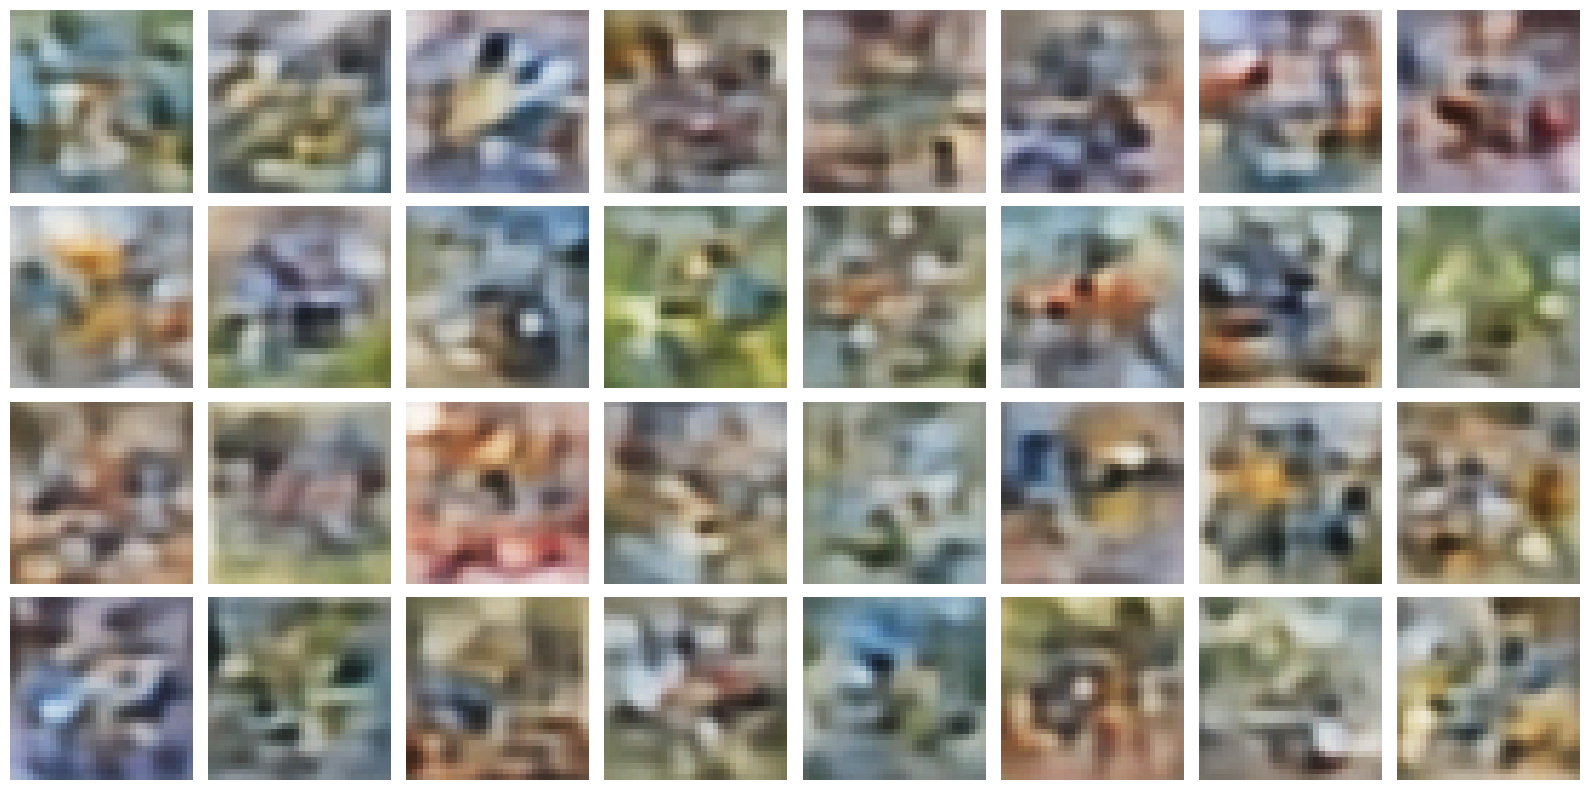

In [13]:
sample_from_prior(model_cifar_kl, n=32, latent_dim=128)

##### Espacio latente (t-SNE)

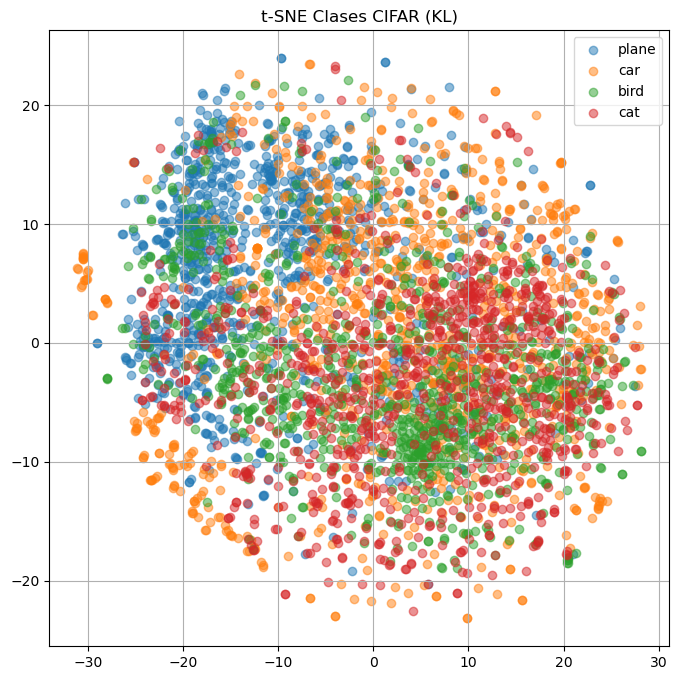

In [14]:
plot_tsne_classes_universal(model_cifar_kl, testloader_cifar, device, classes_names=classes, title="t-SNE Clases CIFAR (KL)")

##### Espacio latente con muestras generadas

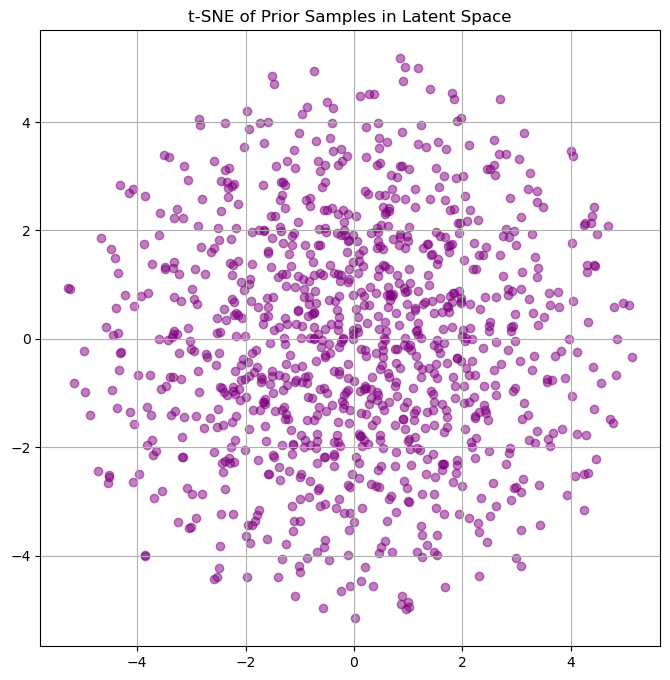

In [15]:
tsne_prior_samples_universal(model_cifar_kl, device, is_cifar=True, latent_dim=128)

##### Espacio latente con recreaciones

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


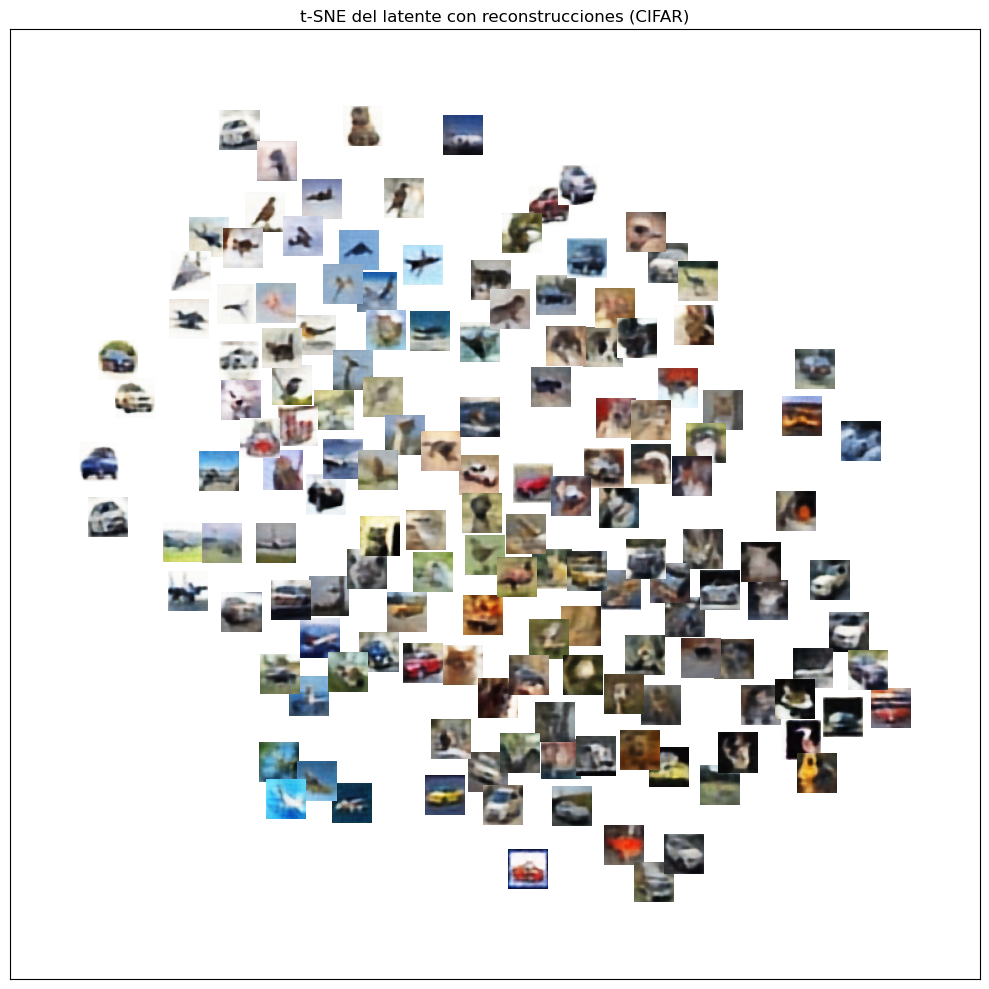

In [16]:
tsne_with_recon_thumbnails_universal(model_cifar_kl, testloader_cifar, device, n_show=150, zoom=0.9)

##### Interpolación

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


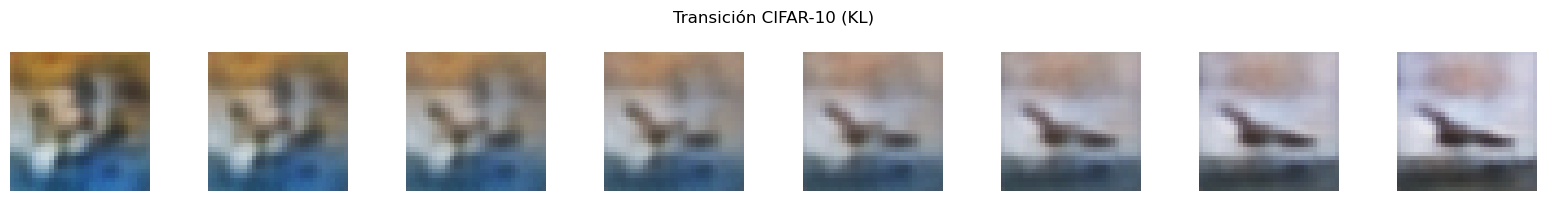

In [17]:
interpolate_universal(model_cifar_kl, testloader_cifar, device, is_cifar=True, title="Transición CIFAR-10 (KL)")

### Modelo WAE (MMD)

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 01 | loss=41486.8925 recon=41154.9728 MMD=331.9197
Epoch 02 | loss=18152.0509 recon=18080.6392 MMD=71.4117
Epoch 03 | loss=14051.0439 recon=13990.9375 MMD=60.1063
Epoch 04 | loss=11953.4553 recon=11901.5104 MMD=51.9449
Epoch 05 | loss=10708.3508 recon=10662.3457 MMD=46.0051
Epoch 06 | loss=9824.9038 recon=9786.0576 MMD=38.8461
Epoch 07 | loss=9230.4605 recon=9195.1120 MMD=35.3485
Epoch 08 | loss=9015.3879 recon=8980.8819 MMD=34.5060
Epoch 09 | loss=8468.2075 recon=8443.7823 MMD=24.4252
Epoch 10 | loss=8496.2125 recon=8466.5728 MMD=29.6397


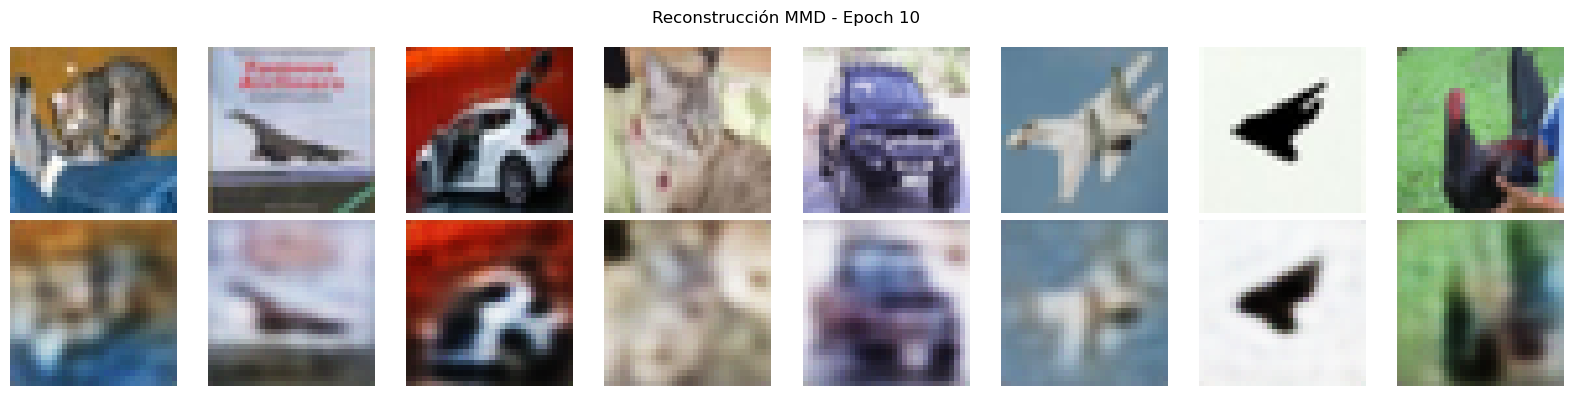

Epoch 11 | loss=8240.3389 recon=8216.3111 MMD=24.0278
Epoch 12 | loss=8230.6021 recon=8207.4788 MMD=23.1233
Epoch 13 | loss=8173.2839 recon=8150.1663 MMD=23.1176
Epoch 14 | loss=8101.4065 recon=8080.0699 MMD=21.3366
Epoch 15 | loss=8054.3188 recon=8034.3170 MMD=20.0017
Epoch 16 | loss=7893.5328 recon=7875.9845 MMD=17.5482
Epoch 17 | loss=7932.2343 recon=7913.5699 MMD=18.6644
Epoch 18 | loss=7830.1864 recon=7814.2092 MMD=15.9772
Epoch 19 | loss=7917.3180 recon=7899.2377 MMD=18.0803
Epoch 20 | loss=7838.7736 recon=7821.5249 MMD=17.2487


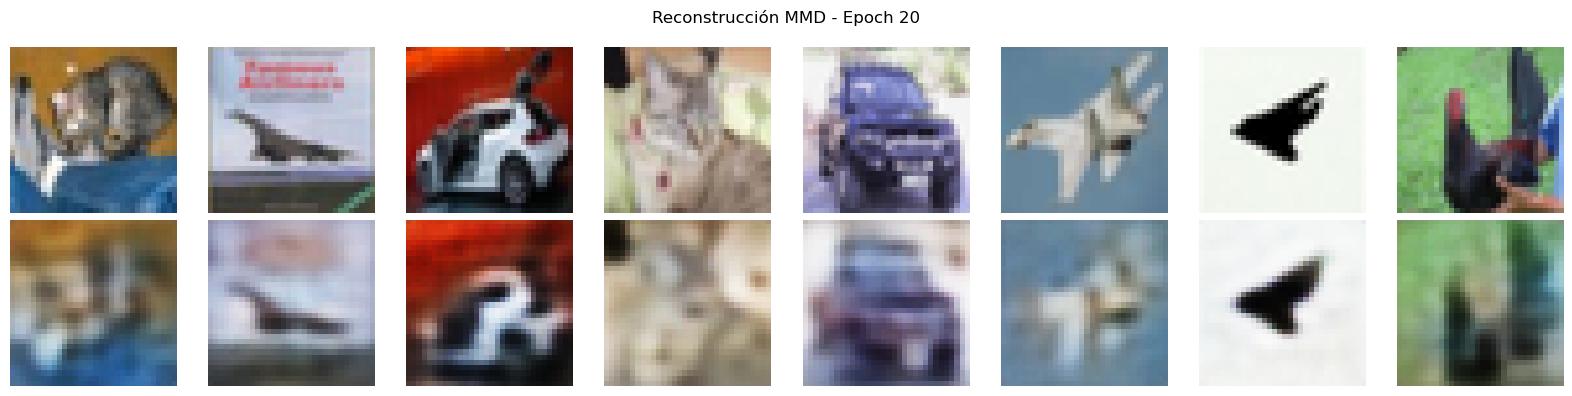

Epoch 21 | loss=7776.7342 recon=7760.9922 MMD=15.7420
Epoch 22 | loss=7654.8937 recon=7639.9195 MMD=14.9742
Epoch 23 | loss=7693.6393 recon=7679.0443 MMD=14.5950
Epoch 24 | loss=7661.5043 recon=7647.0117 MMD=14.4927
Epoch 25 | loss=7652.7828 recon=7638.2500 MMD=14.5329
Epoch 26 | loss=7527.2015 recon=7512.5350 MMD=14.6665
Epoch 27 | loss=7611.9393 recon=7598.4380 MMD=13.5014
Epoch 28 | loss=7528.8504 recon=7514.4235 MMD=14.4270
Epoch 29 | loss=7535.2644 recon=7519.9321 MMD=15.3323
Epoch 30 | loss=7387.9768 recon=7375.2250 MMD=12.7519


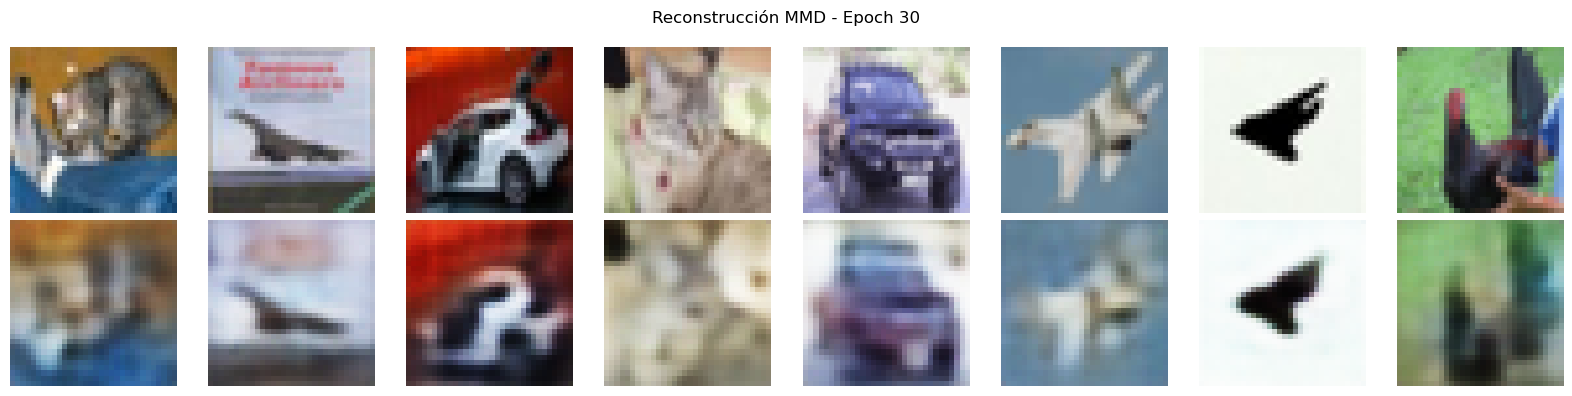

Epoch 31 | loss=7408.4222 recon=7395.7367 MMD=12.6856
Epoch 32 | loss=7354.6713 recon=7342.7001 MMD=11.9712
Epoch 33 | loss=7328.3560 recon=7316.7192 MMD=11.6369
Epoch 34 | loss=7315.9221 recon=7304.0711 MMD=11.8511
Epoch 35 | loss=7322.8117 recon=7310.5302 MMD=12.2815
Epoch 36 | loss=7340.3412 recon=7326.6973 MMD=13.6439
Epoch 37 | loss=7250.6852 recon=7239.2449 MMD=11.4403
Epoch 38 | loss=7202.8336 recon=7191.7583 MMD=11.0753
Epoch 39 | loss=7199.2272 recon=7188.5837 MMD=10.6434
Epoch 40 | loss=7130.1457 recon=7119.4684 MMD=10.6773


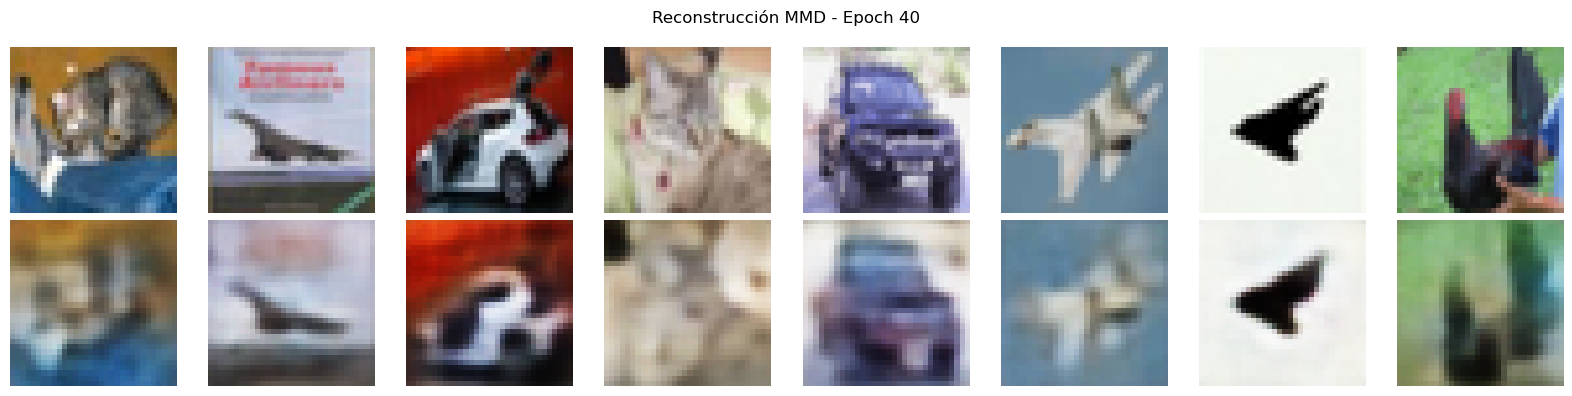

Epoch 41 | loss=7247.5959 recon=7236.8120 MMD=10.7839
Epoch 42 | loss=7219.4843 recon=7207.5971 MMD=11.8872
Epoch 43 | loss=7152.9226 recon=7142.0253 MMD=10.8973
Epoch 44 | loss=7129.3613 recon=7118.9704 MMD=10.3909
Epoch 45 | loss=7034.4760 recon=7024.3526 MMD=10.1234
Epoch 46 | loss=7037.4911 recon=7027.5079 MMD=9.9832
Epoch 47 | loss=6969.5054 recon=6959.9317 MMD=9.5737
Epoch 48 | loss=7049.1366 recon=7039.5225 MMD=9.6142
Epoch 49 | loss=7029.3483 recon=7018.9410 MMD=10.4072
Epoch 50 | loss=7055.1488 recon=7044.9761 MMD=10.1727


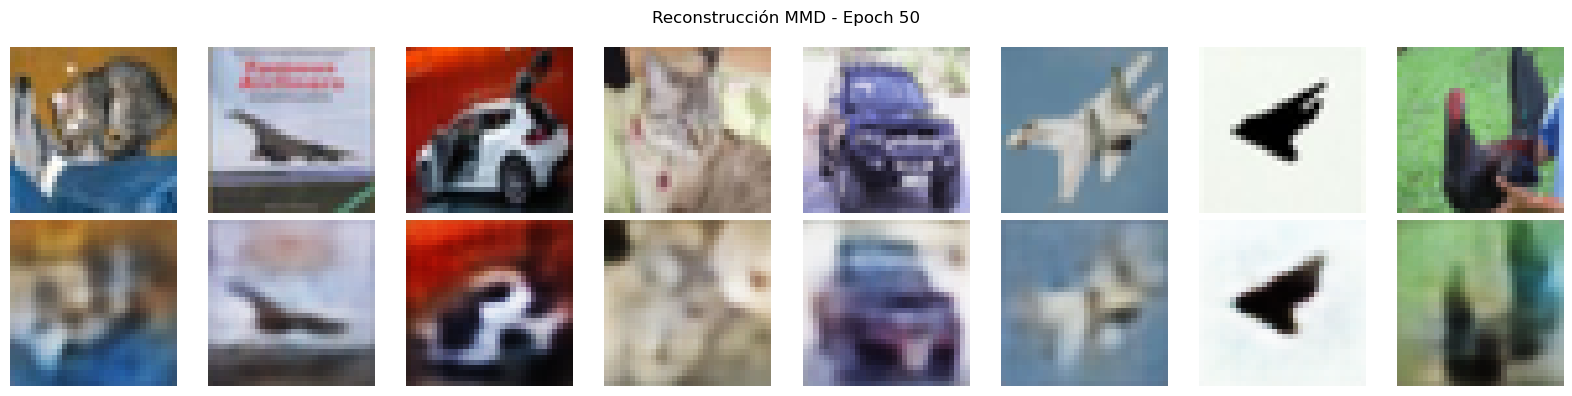

In [11]:
latent_dim = 128
model_cifar_mmd = CIFARWAE(latent_dim).to(device)

hist_loss_cifar_mmd, hist_rec_cifar_mmd, hist_cifar_mmd = train_model(model_cifar_mmd, trainloader_cifar, testloader_cifar, device, epochs=50, loss_type='mmd', weight=10000.0)

##### Curvas de aprendizaje

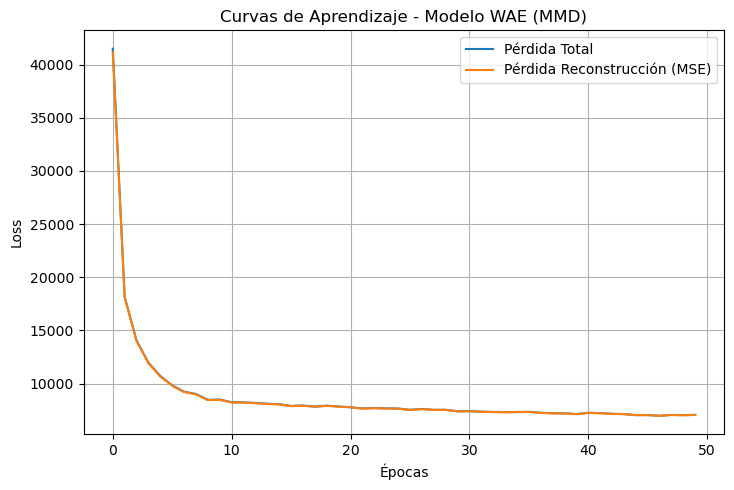

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 2)
plt.plot(hist_loss_cifar_mmd, label='Pérdida Total')
plt.plot(hist_rec_cifar_mmd, label='Pérdida Reconstrucción (MSE)')
plt.title('Curvas de Aprendizaje - Modelo WAE (MMD)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##### Generación de nuevos datos

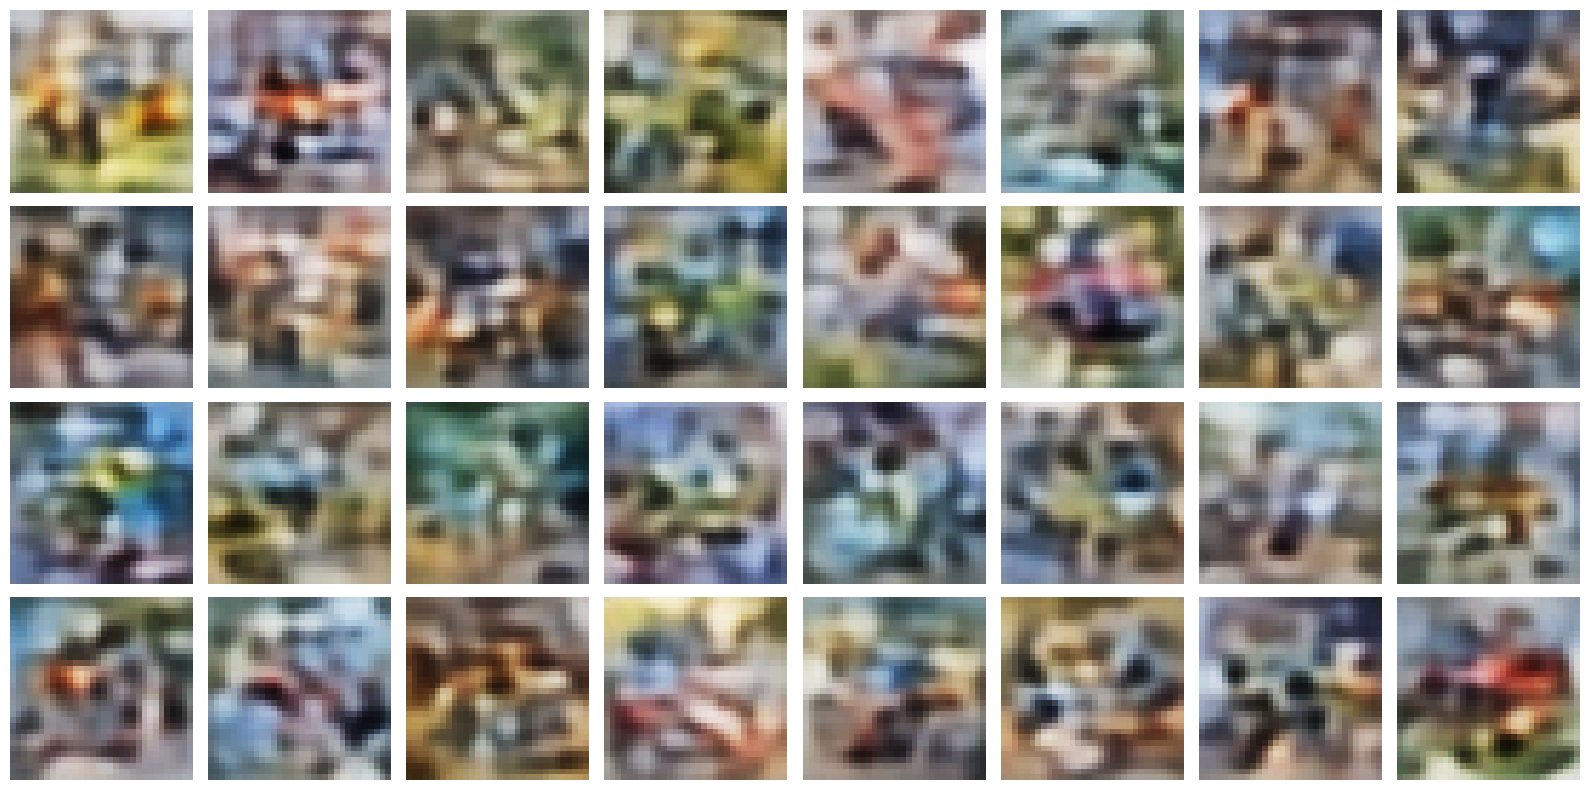

In [19]:
sample_from_prior(model_cifar_mmd, n=32, latent_dim=128)

##### Espacio latente (t-SNE)

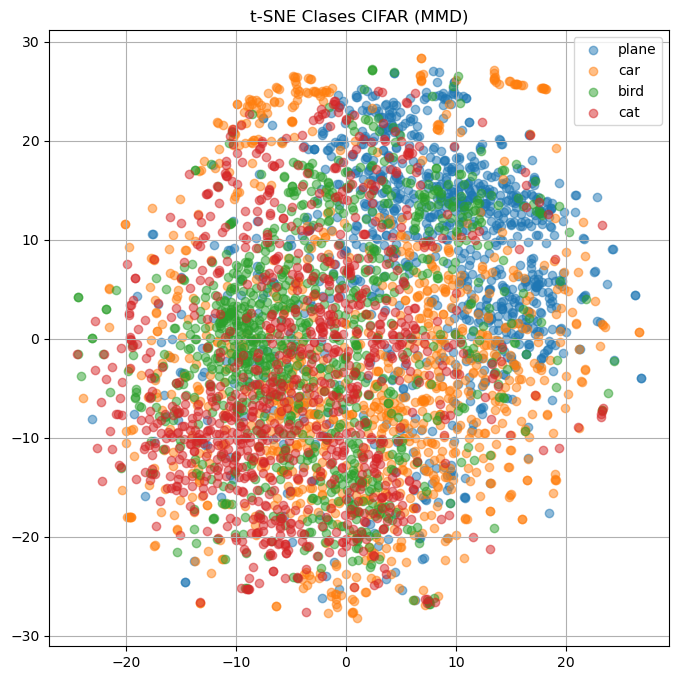

In [20]:
plot_tsne_classes_universal(model_cifar_mmd, testloader_cifar, device, classes_names=classes, title="t-SNE Clases CIFAR (MMD)")

##### Espacio latente con muestras generadas

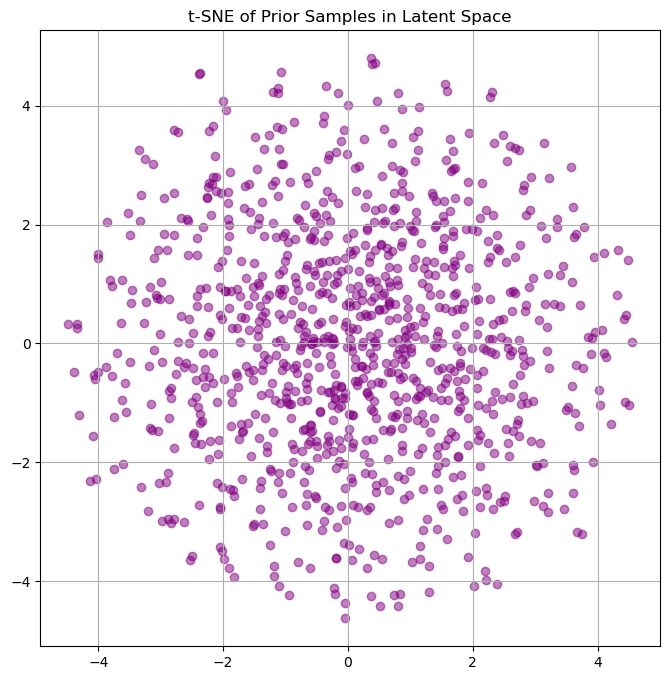

In [21]:
tsne_prior_samples_universal(model_cifar_mmd, device, is_cifar=True, latent_dim=128)

##### Espacio latente con recreaciones

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


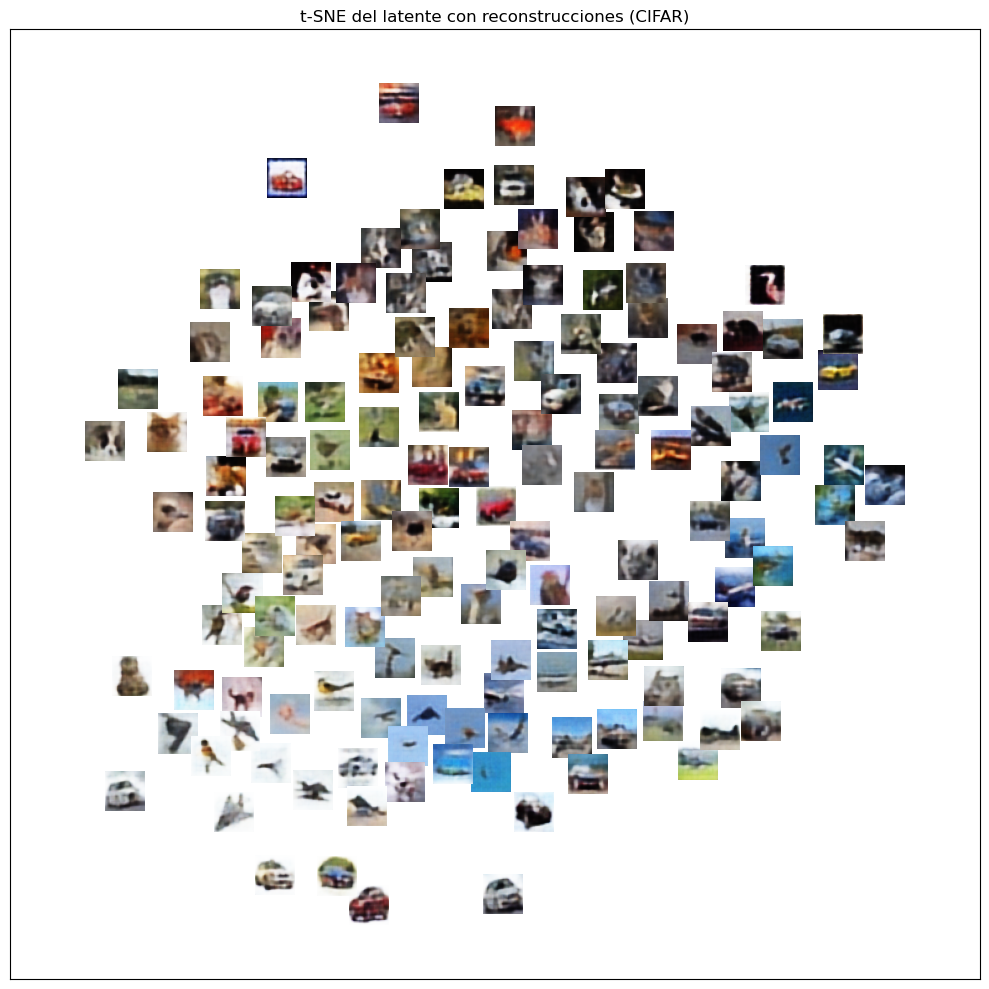

In [22]:
tsne_with_recon_thumbnails_universal(model_cifar_mmd, testloader_cifar, device, n_show=150, zoom=0.9)

##### Interpolación

c:\Users\pepov\anaconda\envs\RNAP\lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


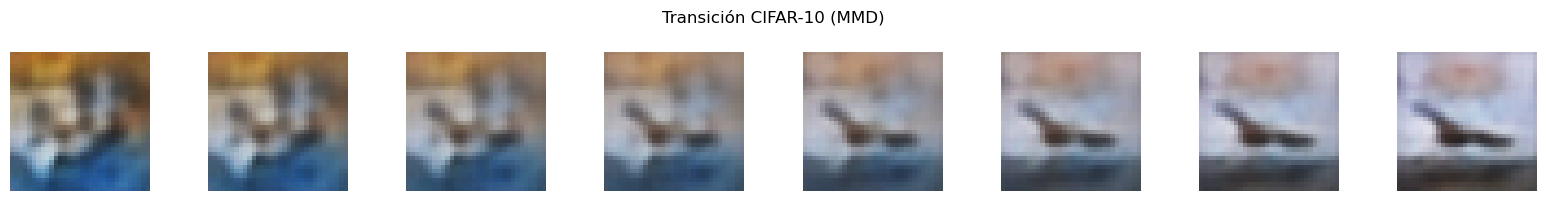

In [23]:
interpolate_universal(model_cifar_mmd, testloader_cifar, device, is_cifar=True, title="Transición CIFAR-10 (MMD)")